# InfraScan: AI-Powered Crack and Damage Assessment for Civil Infrastructure

**Student:** Bhumika Bhatt  
**Institution:** Graphic Era Deemed to be University, Dehradun, Uttarakhand

This notebook contains the complete InfraScan workflow: dataset auditing and cleaning, a leakage-safe data split, a ResNet18 crack classifier, a YOLOv8n-seg crack segmentation model, and an inference pipeline that runs both models on an input image. The code was executed on Google Colab (Tesla T4 GPU), with Google Drive used for storage.

| No. | Section |
|---|---|
| 1 | Project Overview |
| 2 | Problem Statement |
| 3 | Objectives |
| 4 | Environment and Dependencies |
| 5 | Dataset Overview |
| 6 | SDNET2018 Audit and Exploration |
| 7 | Data Cleaning and Metadata Preparation |
| 8 | Dataset Splitting and Validation |
| 9 | Classification Model: ResNet18 |
| 10 | Classification Training |
| 11 | Classification Evaluation and Results |
| 12 | Segmentation Dataset Preparation |
| 13 | Segmentation Model: YOLOv8n-seg |
| 14 | Segmentation Training |
| 15 | Segmentation Evaluation and Results |
| 16 | Results Summary and Saved Artifacts |
| 17 | Integrated Inference Pipeline |
| 18 | Sample Predictions and Output Analysis |
| 19 | Standalone Inference Script |
| 20 | Limitations |
| 21 | Future Improvements |
| 22 | Conclusion |

## 1. Project Overview

InfraScan is a prototype for automated crack inspection of concrete surfaces such as bridge decks, walls and pavements. It consists of two independent deep-learning models that answer two different questions about an image.

| | Classification | Segmentation |
|---|---|---|
| Question answered | Does this image contain a crack? | Where are the cracks and what shape do they have? |
| Model | ResNet18 (ImageNet-pretrained, fine-tuned) | YOLOv8n-seg (COCO-pretrained, fine-tuned) |
| Dataset | SDNET2018 (56,077 images after cleaning) | Crack-Seg (4,029 images) |
| Labels | One label per image: cracked or uncracked | One polygon outline per crack |
| Output | Class and confidence | Crack instances with masks and boxes |
| Test set | 8,784 images | 112 images |

**Why two models.** The two datasets carry different kinds of labels. SDNET2018 only states whether a 256 x 256 px image contains a crack; it does not show where the crack is. Crack-Seg provides polygon outlines, which are needed to learn the shape and position of cracks. Because image-level labels and polygon labels cannot be merged into one training set, each task has its own model, its own data split and its own evaluation. The models are combined only at inference time (Sections 17 to 19), where both are applied to the same image and their outputs are reported side by side.

**Evaluation scope.** Classification results (Section 11) and segmentation results (Section 15) are reported separately, because they use different test sets and different metrics. The notebook does not contain an evaluation of the integrated pipeline as a whole, so no single overall accuracy is given for it.

## 2. Problem Statement

Cracks are a common sign of deterioration in concrete structures, and regular visual inspection is the usual way to find them. Manual inspection is slow and depends on the inspector's judgement, which makes it hard to apply consistently over large surfaces. Automatic analysis of inspection images can support the inspector by flagging images that contain cracks and by showing where the cracks are.

Detecting cracks in images is difficult in practice. The SDNET2018 documentation states that the cracks range from 0.06 mm to 25 mm in width and that the images contain shadows, surface roughness, scaling, edges, holes and debris, all of which can resemble cracks or hide them. The task addressed here has two parts: decide whether an image shows a crack, and localise the crack when it does.

## 3. Objectives

1. Audit the two datasets, identify duplicate and conflicting files, and prepare clean metadata for SDNET2018.
2. Build a train/validation/test split of SDNET2018 in which related photographs never appear in more than one partition.
3. Fine-tune ResNet18 as a binary crack classifier and measure its performance on a held-out test split.
4. Fine-tune YOLOv8n-seg on Crack-Seg and measure box and mask performance on its test split.
5. Combine both models in an inference pipeline that reports a classification result and a segmentation overlay for an input image, and save it as a command-line script.
6. Report the results of each model separately and state the limitations of the current work.

## 4. Environment and Dependencies

The notebook was run on Google Colab. The dataset archives, the split file, the model checkpoints and the results are stored on Google Drive so that they survive runtime restarts. Extracted images are placed on the local runtime disk (`/content`). The runtime was restarted several times during the project, so the outputs in this notebook come from more than one Colab session, and the execution counters shown beside the cells are those of the original sessions and are not consecutive.

**Software versions recorded in the outputs**

| Component | Version |
|---|---|
| Python | 3.13.16 |
| PyTorch | 2.11.0+cu130 |
| scikit-learn | 1.6.1 |
| NumPy | 2.4.6 |
| pandas | 2.2.3 |
| Pillow | 11.3.0 |
| Ultralytics | 8.4.203 |
| GPU | Tesla T4 |

The notebook relies on the Colab runtime for PyTorch, pandas and scikit-learn. The only package it installs is Ultralytics (Section 13.2).

**Storage layout**

| Content | Location |
|---|---|
| Dataset archives | `/content/drive/MyDrive/Infrascan_Datasets/` |
| Extracted SDNET2018 images | `/content/sdnet2018_raw/` (local runtime) |
| Extracted Crack-Seg dataset | `/content/InfraScan_YOLO/` (local runtime) |
| Classification split file and metrics | `/content/drive/MyDrive/InfraScan/classification/outputs/` |
| ResNet18 checkpoint | `/content/drive/MyDrive/InfraScan/classification/checkpoints/` |
| Segmentation runs, test evaluation and predictions | `/content/drive/MyDrive/InfraScan/segmentation/` |
| Integrated inference outputs and script | `/content/drive/MyDrive/InfraScan/combined_inference/` |

**Notes on re-running the notebook**

- The cell that saves the split file refuses to overwrite an existing `split_v1.csv`, so the split behind all reported results stays fixed.
- The ResNet18 training cell overwrites `resnet18_best.pth`, and the YOLO training cell overwrites the run folder `yolov8n_seg_run1`. Running them again retrains the models and replaces the checkpoints behind the reported results.
- The data split and the YOLO training use seed 42. The ResNet18 training loop does not set a seed, so a repeated run would not reproduce the reported numbers exactly.
- Later cells reuse variables defined in earlier cells, so the cells are meant to be run in the order shown. Because of the points above, the notebook is best read as a record of the executed runs rather than re-run in full.

### 4.1 Mount Google Drive

Mounts Google Drive to read the datasets and to store results. A sign-in prompt appears the first time.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 4.2 Check the runtime

Prints the PyTorch version and checks that a GPU is available for training.

In [19]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not enabled. Go to Runtime > Change runtime type > T4 GPU.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 5. Dataset Overview

Two public datasets are used, one for each task.

| | SDNET2018 | Crack-Seg |
|---|---|---|
| Task | Crack classification | Crack segmentation |
| Source | Utah State University (M. Maguire, S. Dorafshan, R. J. Thomas) | Ultralytics Crack-seg dataset |
| Content | 56,092 colour images (256 x 256 px) of bridge decks, walls and pavements | 4,029 images with polygon annotations |
| Labels | Each image is labelled cracked (C) or uncracked (U) | One class, `crack`, drawn as polygons |
| Provided structure | Folders by surface (D, P, W) and class (C, U) | Ready-made train, val and test folders (3,717 / 200 / 112 images) |
| Used for | ResNet18 (Sections 6 to 11) | YOLOv8n-seg (Sections 12 to 15) |

SDNET2018 was created by photographing 230 concrete surfaces (54 bridge decks, 72 walls and 104 pavements) with a 16 MP camera and cutting each photograph into 256 x 256 px sub-images. Many sub-images therefore come from the same photograph and are not independent of each other. This shapes the data splitting in Section 8.

The next four steps confirm that the archives are present, intact and structured as expected.

### 5.1 Dataset archives

Lists the files in the dataset folder on Google Drive.

In [ ]:
import os

base = "/content/drive/MyDrive/Infrascan_Datasets"

for root, dirs, files in os.walk(base):
    print(root)
    for file in files:
        print("  ", file)

/content/drive/MyDrive/Infrascan_Datasets
   DATA_Maguire_20180517_ALL.zip
   crack-seg.zip


### 5.2 Archive integrity check

Reads every entry of both archives and verifies its checksum (CRC) to rule out corrupted files.

In [ ]:
import zipfile, time
from pathlib import Path

base = Path("/content/drive/MyDrive/Infrascan_Datasets")

for name in ["DATA_Maguire_20180517_ALL.zip", "crack-seg.zip"]:
    p = base / name
    print("=" * 60)
    print(name)
    print("exists:", p.exists())
    if not p.exists():
        continue

    size = p.stat().st_size
    print(f"size: {size:,} bytes = {size / 1024**2:.1f} MB")

    start = time.time()
    with zipfile.ZipFile(p) as z:          # opens the zip read-only
        print("entries inside:", len(z.infolist()))
        bad = z.testzip()                  # reads every entry and checks its checksum (CRC)
        print("integrity check:", "OK - no corrupt entries" if bad is None else f"CORRUPT entry: {bad}")
    print(f"took {time.time() - start:.0f} seconds")

DATA_Maguire_20180517_ALL.zip
exists: True
size: 528,286,896 bytes = 503.8 MB
entries inside: 2
integrity check: OK - no corrupt entries
took 11 seconds
crack-seg.zip
exists: True
size: 96,089,865 bytes = 91.6 MB
entries inside: 8067
integrity check: OK - no corrupt entries
took 5 seconds


Both archives pass the check. The SDNET2018 download is a zip file that contains a second zip file with the images. The inner archive is verified in Section 6.3 before it is extracted.

### 5.3 Archive structure

Inspects both archives without extracting them to disk (the inner SDNET2018 archive is read in memory). For Crack-Seg the cell counts the images and labels in each split and checks that every image has a label file of the same name.

In [7]:
import zipfile, io, collections
from pathlib import Path, PurePosixPath

base = Path("/content/drive/MyDrive/Infrascan_Datasets")

# ---------------- PART A: SDNET2018 (zip inside a zip, read in memory) ----------------
print("=" * 60)
print("PART A: DATA_Maguire_20180517_ALL.zip")
with zipfile.ZipFile(base / "DATA_Maguire_20180517_ALL.zip") as outer:
    for i in outer.infolist():
        print(f"  outer entry: {i.filename}  ({i.file_size / 1024**2:.1f} MB)")
    inner_names = [i.filename for i in outer.infolist() if i.filename.endswith("SDNET2018.zip")]
    if not inner_names:
        print("No inner SDNET2018.zip found - stop here and show me this output.")
    else:
        data = outer.read(inner_names[0])      # held in RAM only, nothing is written to disk
        with zipfile.ZipFile(io.BytesIO(data)) as inner:
            files = [i for i in inner.infolist() if not i.is_dir()]
            print("\ninner SDNET2018.zip: files =", len(files))
            print("extensions:", dict(collections.Counter(PurePosixPath(i.filename).suffix.lower() for i in files)))
            print("\nfiles per folder:")
            per_folder = collections.Counter(str(PurePosixPath(i.filename).parent) for i in files)
            for folder, n in sorted(per_folder.items())[:30]:
                print(f"  {folder}: {n}")
            print("\nfirst 3 file names:", [i.filename for i in files[:3]])
        del data

# ---------------- PART B: Crack-Seg ----------------
print("\n" + "=" * 60)
print("PART B: crack-seg.zip")
with zipfile.ZipFile(base / "crack-seg.zip") as z:
    files = [i for i in z.infolist() if not i.is_dir()]
    print("files =", len(files))
    print("first 5 names:", [i.filename for i in files[:5]])

    counts = collections.Counter()
    stems = collections.defaultdict(lambda: {"images": set(), "labels": set()})
    others = []
    for i in files:
        parts = PurePosixPath(i.filename).parts
        split = next((p for p in parts if p in ("train", "valid", "val", "test")), None)
        kind = next((p for p in parts if p in ("images", "labels")), None)
        if split and kind:
            counts[(split, kind)] += 1
            stems[split][kind].add(PurePosixPath(i.filename).stem)
        else:
            others.append(i.filename)

    print("\ncounts per split/kind:")
    for k, n in sorted(counts.items()):
        print(f"  {k}: {n}")
    print("\npairing check (image names vs label names, by name only):")
    for split, d in stems.items():
        print(f"  {split}: images without label={len(d['images'] - d['labels'])}, labels without image={len(d['labels'] - d['images'])}")
    print("\nfiles outside split folders:", others)

    yaml_names = [n for n in others if n.endswith(".yaml")]
    for n in yaml_names:
        print(f"\n--- {n} ---")
        print(z.read(n).decode("utf-8", errors="replace")[:1500])

    empty = [i.filename for i in files if "labels" in i.filename and i.file_size == 0]
    print("\nzero-byte label files:", empty)

PART A: DATA_Maguire_20180517_ALL.zip
  outer entry: DATA_Maguire_20180517_ALL/ReadMe_SDNET2018 .txt  (0.0 MB)
  outer entry: DATA_Maguire_20180517_ALL/SDNET2018.zip  (503.8 MB)

inner SDNET2018.zip: files = 56092
extensions: {'.jpg': 56092}

files per folder:
  D/CD: 2025
  D/UD: 11595
  P/CP: 2608
  P/UP: 21726
  W/CW: 3851
  W/UW: 14287

first 3 file names: ['P/CP/001-100.jpg', 'P/CP/001-101.jpg', 'P/CP/001-102.jpg']

PART B: crack-seg.zip
files = 8059
first 5 names: ['images/test/1616.rf.c868709931a671796794fdbb95352c5a.jpg', 'images/test/1675.rf.e3aa3f8d28d0247ef0284dd46dacc29f.jpg', 'images/test/1686.rf.809fb1b51c607e5cf787e44ef4ddd7b8.jpg', 'images/test/1706.rf.011d213c21ec78896c36728dcbc156f5.jpg', 'images/test/1716.rf.85ea38b36008beaa72c5d8541f734eb0.jpg']

counts per split/kind:
  ('test', 'images'): 112
  ('test', 'labels'): 112
  ('train', 'images'): 3717
  ('train', 'labels'): 3717
  ('val', 'images'): 200
  ('val', 'labels'): 200

pairing check (image names vs label names

SDNET2018 contains 56,092 JPEG files in six folders (surface D, P or W, each with a cracked and an uncracked folder). Crack-Seg contains 4,029 image and label pairs with no unmatched files: 3,717 for training, 200 for validation and 112 for testing. One validation label file is empty, which means that image has no annotated crack.

The comment lines in the Crack-Seg YAML file state the validation and test image counts the other way round (112 and 200). The folders, which are what the code uses, contain 200 validation and 112 test images.

### 5.4 SDNET2018 documentation and class counts

Prints the dataset ReadMe and the number of images in each folder of the inner archive.

In [ ]:
import zipfile, collections, os, time

outer_path = "/content/drive/MyDrive/Infrascan_Datasets/DATA_Maguire_20180517_ALL.zip"
assert os.path.isfile(outer_path), "outer zip missing"
t0 = time.time()

with zipfile.ZipFile(outer_path) as outer:
    # 1) ReadMe text
    readme_name = [n for n in outer.namelist() if n.lower().endswith(".txt")][0]
    print("=== ReadMe:", readme_name, "===")
    print(outer.read(readme_name).decode("utf-8", errors="replace"))

    # 2) Inner zip: read only its table of contents
    inner_name = [n for n in outer.namelist() if n.lower().endswith(".zip")][0]
    print("\n=== Inner zip:", inner_name, "===")
    print("compress type in outer zip (0 = stored):", outer.getinfo(inner_name).compress_type)
    with outer.open(inner_name) as f, zipfile.ZipFile(f) as inner:
        infos = [i for i in inner.infolist() if not i.is_dir()]
        print("files inside inner zip:", f"{len(infos):,}")
        print("uncompressed size     :", f"{sum(i.file_size for i in infos):,} bytes")
        print("file types            :", dict(collections.Counter(
            os.path.splitext(i.filename)[1].lower() for i in infos).most_common(6)))

        per_folder = collections.Counter(os.path.dirname(i.filename) for i in infos)
        print("\nfiles per folder:")
        for folder, n in sorted(per_folder.items()):
            print(f"   {n:>7,}  {folder}")
        print("\nfirst 3 file names:")
        for i in infos[:3]:
            print("   ", i.filename)

print(f"\ndone in {time.time() - t0:.0f} s")

=== ReadMe: DATA_Maguire_20180517_ALL/ReadMe_SDNET2018 .txt ===

Dataset Title: 
SDNET2018: A concrete crack image dataset for machine learning applications

Researchers:
Marc Maguire
Utah State University
Utah State University, Department of Civil and Environmental Engineering, 4110 Old Main Hill, Logan, Utah, 84321-4110.
m.maguire@usu.edu
http://orcid.org/0000-0002-7897-0344?lang=en

Name and contact information of Co-PI:
Sattar Dorafshan
Utah State University
Utah State University, Department of Civil and Environmental Engineering, 4110 Old Main Hill, Logan, Utah, 84321-4110.
sattar.dor@aggiemail.usu.edu

Name and contact information of Co-PI:
Robert J. Thomas
Utah State University
Utah State University, Department of Civil and Environmental Engineering, 4110 Old Main Hill, Logan, Utah, 84321-4110.
robert.thomas@aggiemail.usu.edu

Project summary, description or abstract:
SDNET2018 is an annotated image dataset for training, validation, and benchmarking of artificial intelligence ba

| Surface | Cracked | Uncracked | Total |
|---|---|---|---|
| Bridge deck (D) | 2,025 | 11,595 | 13,620 |
| Pavement (P) | 2,608 | 21,726 | 24,334 |
| Wall (W) | 3,851 | 14,287 | 18,138 |
| Total | 8,484 | 47,608 | 56,092 |

Only about 15% of the images are cracked, so the dataset is imbalanced. This affects how the classification results must be read (Section 11).

## 6. SDNET2018 Audit and Exploration

Before training, the SDNET2018 files are checked for naming irregularities, duplicates and labelling conflicts. They are then extracted and inspected.

### 6.1 File naming and photograph counts

Each file should be named `<photo>-<patch>.jpg` and sit in the folder that matches its surface letter. The cell checks this pattern and compares the number of distinct photographs per surface with the ReadMe (54 decks, 72 walls, 104 pavements).

In [ ]:
import zipfile, re, collections, os

outer_path = "/content/drive/MyDrive/Infrascan_Datasets/DATA_Maguire_20180517_ALL.zip"
pat = re.compile(r"^([DPW])/(C|U)([DPW])/(\d+)-(\d+)\.jpg$", re.IGNORECASE)

with zipfile.ZipFile(outer_path) as outer:
    inner_name = [n for n in outer.namelist() if n.lower().endswith(".zip")][0]
    with outer.open(inner_name) as f, zipfile.ZipFile(f) as inner:
        names = [i.filename for i in inner.infolist() if not i.is_dir()]

print("total files:", f"{len(names):,}")
print("unique full paths:", f"{len(set(names)):,}")

parsed, bad = [], []
for n in names:
    m = pat.match(n)
    (parsed if m else bad).append(m.groups() if m else n)

print("names matching pattern:", f"{len(parsed):,}")
print("names NOT matching    :", len(bad))
for n in bad[:10]:
    print("   ", n)

# folder letter must agree with file's own surface letter
mismatch = [p for p in parsed if p[0].upper() != p[2].upper()]
print("folder/surface letter mismatches:", len(mismatch))

# unique photo numbers per surface (C and U together)
prefixes = collections.defaultdict(set)
by_class = collections.defaultdict(lambda: collections.defaultdict(set))
for surf, cls, _, pre, suf in parsed:
    prefixes[surf.upper()].add(pre)
    by_class[surf.upper()][cls.upper()].add(pre)

expected = {"D": 54, "W": 72, "P": 104}
print("\nunique photo numbers per surface (ReadMe says 54 / 72 / 104):")
for s in "DWP":
    both = by_class[s]["C"] & by_class[s]["U"]
    print(f"  {s}: {len(prefixes[s]):>4} unique   expected {expected[s]:>3}   "
          f"in cracked folder: {len(by_class[s]['C'])}   in uncracked folder: {len(by_class[s]['U'])}   "
          f"in BOTH: {len(both)}")

print("\nexample prefixes (first 8 per surface):")
for s in "DWP":
    print(f"  {s}:", sorted(prefixes[s])[:8])

total files: 56,092
unique full paths: 56,092
names matching pattern: 56,042
names NOT matching    : 50
    P/CP/027-1_2.jpg
    P/CP/027-20_2.jpg
    P/CP/027-21_2.jpg
    P/CP/027-22_2.jpg
    P/CP/027-2_2.jpg
    P/CP/027-40_2.jpg
    P/CP/027-41_2.jpg
    P/CP/027-59_2.jpg
    P/CP/027-60_2.jpg
    P/CP/027-61_2.jpg
folder/surface letter mismatches: 0

unique photo numbers per surface (ReadMe says 54 / 72 / 104):
  D:   54 unique   expected  54   in cracked folder: 54   in uncracked folder: 54   in BOTH: 54
  W:   72 unique   expected  72   in cracked folder: 72   in uncracked folder: 72   in BOTH: 72
  P:  104 unique   expected 104   in cracked folder: 99   in uncracked folder: 104   in BOTH: 99

example prefixes (first 8 per surface):
  D: ['7001', '7002', '7003', '7004', '7005', '7006', '7007', '7008']
  W: ['7069', '7070', '7071', '7072', '7073', '7074', '7075', '7076']
  P: ['001', '002', '003', '004', '005', '006', '007', '008']


56,042 of the 56,092 files follow the standard pattern. The other 50 carry an extra `_2` suffix and are examined next. Folder letters and file surface letters never disagree, and the photograph counts match the ReadMe for all three surfaces. Only 99 of the 104 pavement photographs have any cracked patch, so five pavement photographs contain no cracks.

### 6.2 Duplicate and conflicting files

**Odd file names and exact duplicates.** Compares each `_2` file with the file of the same name without the suffix, and searches all 56,092 files for exact duplicates using the CRC32 checksum and size stored in the archive.

In [ ]:
import zipfile, re, collections

outer_path = "/content/drive/MyDrive/Infrascan_Datasets/DATA_Maguire_20180517_ALL.zip"
normal = re.compile(r"^([DPW])/(C|U)([DPW])/(\d+)-(\d+)\.jpg$", re.IGNORECASE)
odd    = re.compile(r"^([DPW])/(C|U)([DPW])/(\d+)-(\d+)_(\d+)\.jpg$", re.IGNORECASE)

with zipfile.ZipFile(outer_path) as outer:
    inner_name = [n for n in outer.namelist() if n.lower().endswith(".zip")][0]
    with outer.open(inner_name) as f, zipfile.ZipFile(f) as inner:
        infos = {i.filename: (i.CRC, i.file_size) for i in inner.infolist() if not i.is_dir()}

odd_names = sorted(n for n in infos if not normal.match(n))
print("odd-named files:", len(odd_names))
assert all(odd.match(n) for n in odd_names), "some odd names have yet another pattern"

# ---- Part 1: the 50 odd files ----
print("\nfolders of odd files:", dict(collections.Counter(n.rsplit('/', 1)[0] for n in odd_names)))
print("photo numbers of odd files:", sorted({odd.match(n).group(4) for n in odd_names}))
print("\nodd file -> normal counterpart? -> same content?")
same = diff = missing = 0
for n in odd_names:
    s, c, _, pre, num, k = odd.match(n).groups()
    twin = f"{s}/{c}{s}/{pre}-{num}.jpg"
    if twin not in infos:
        missing += 1; status = "no counterpart"
    elif infos[twin] == infos[n]:
        same += 1; status = "IDENTICAL content"
    else:
        diff += 1; status = "counterpart exists, content differs"
    print(f"  {n:<22} {status}")
print(f"\nsummary: identical={same}  differs={diff}  no counterpart={missing}")

# ---- Part 2: exact duplicates across ALL files (CRC32 + size) ----
groups = collections.defaultdict(list)
for n, key in infos.items():
    groups[key].append(n)
dups = {k: v for k, v in groups.items() if len(v) > 1}
print(f"\nexact-duplicate groups (same CRC32 + size): {len(dups)}")
print("files involved in them:", sum(len(v) for v in dups.values()))
def klass(n): return n.split('/')[1][0].upper()
cross = [v for v in dups.values() if len({klass(n) for n in v}) > 1]
print("groups mixing cracked and uncracked:", len(cross))
for v in list(dups.values())[:8]:
    print("  ", v)

odd-named files: 50

folders of odd files: {'D/CD': 3, 'D/UD': 9, 'P/CP': 13, 'W/CW': 22, 'W/UW': 3}
photo numbers of odd files: ['027', '7039', '7053', '7074', '7107', '7140']

odd file -> normal counterpart? -> same content?
  D/CD/7039-110_2.jpg    IDENTICAL content
  D/CD/7039-111_2.jpg    IDENTICAL content
  D/CD/7039-113_2.jpg    IDENTICAL content
  D/UD/7039-112_2.jpg    no counterpart
  D/UD/7053-17_2.jpg     IDENTICAL content
  D/UD/7053-18_2.jpg     IDENTICAL content
  D/UD/7053-35_2.jpg     IDENTICAL content
  D/UD/7053-36_2.jpg     IDENTICAL content
  D/UD/7053-53_2.jpg     IDENTICAL content
  D/UD/7053-54_2.jpg     IDENTICAL content
  D/UD/7053-89_2.jpg     IDENTICAL content
  D/UD/7053-90_2.jpg     IDENTICAL content
  P/CP/027-1_2.jpg       no counterpart
  P/CP/027-20_2.jpg      no counterpart
  P/CP/027-21_2.jpg      no counterpart
  P/CP/027-22_2.jpg      no counterpart
  P/CP/027-2_2.jpg       no counterpart
  P/CP/027-40_2.jpg      no counterpart
  P/CP/027-41_2.jpg 

Of the 50 `_2` files, 11 are identical copies of a normal-named file in the same folder, and 39 have no such counterpart. Across the whole dataset there are 13 groups of exact duplicates (26 files). In two of these groups the same image appears in both a cracked and an uncracked folder.

**SHA-256 confirmation.** Compares SHA-256 hashes for the 13 duplicate groups, because CRC32 alone can in principle produce false matches. The cell also lists the `_2` files that are not part of any duplicate group.

In [ ]:
import zipfile, re, collections, hashlib

outer_path = "/content/drive/MyDrive/Infrascan_Datasets/DATA_Maguire_20180517_ALL.zip"
normal = re.compile(r"^([DPW])/(C|U)([DPW])/(\d+)-(\d+)\.jpg$", re.IGNORECASE)
odd    = re.compile(r"^([DPW])/(C|U)([DPW])/(\d+)-(\d+)_(\d+)\.jpg$", re.IGNORECASE)

with zipfile.ZipFile(outer_path) as outer:
    inner_name = [n for n in outer.namelist() if n.lower().endswith(".zip")][0]
    with outer.open(inner_name) as f, zipfile.ZipFile(f) as inner:
        infos = {i.filename: (i.CRC, i.file_size) for i in inner.infolist() if not i.is_dir()}

        groups = collections.defaultdict(list)
        for n, key in infos.items():
            groups[key].append(n)
        dups = {k: v for k, v in groups.items() if len(v) > 1}
        assert len(dups) == 13, f"expected 13 groups, got {len(dups)}"

        print("=== SHA-256 check of the 13 duplicate groups ===")
        confirmed = 0
        for v in sorted(dups.values()):
            hashes = {n: hashlib.sha256(inner.read(n)).hexdigest() for n in v}
            same = len(set(hashes.values())) == 1
            confirmed += same
            labels = sorted({n.split('/')[1][0].upper() for n in v})
            tag = "LABEL CONFLICT" if len(labels) > 1 else "same label"
            print(f"  {'OK ' if same else 'DIFF'} {tag:<14} {v}")
        print(f"SHA-256 confirmed identical: {confirmed} of {len(dups)} groups")

in_dup = {n for v in dups.values() for n in v}
odd_names = sorted(n for n in infos if not normal.match(n))
unmatched = [n for n in odd_names if n not in in_dup]
print("\n=== odd files with no exact duplicate:", len(unmatched), "===")
rows = collections.Counter()
for n in unmatched:
    s, c, _, pre, num, k = odd.match(n).groups()
    other = "U" if c.upper() == "C" else "C"
    same_folder  = f"{s}/{c}{s}/{pre}-{num}.jpg" in infos
    other_folder = f"{s}/{other}{s}/{pre}-{num}.jpg" in infos
    rows[(same_folder, other_folder)] += 1
    if other_folder or same_folder:
        print("  has normal-named file:", n, "same_folder" if same_folder else "OTHER folder")
print("(normal file in same folder, normal file in other folder) -> count")
for k, v in sorted(rows.items()):
    print("  ", k, "->", v)

=== SHA-256 check of the 13 duplicate groups ===
  OK  same label     ['D/CD/7039-110.jpg', 'D/CD/7039-110_2.jpg']
  OK  same label     ['D/CD/7039-111.jpg', 'D/CD/7039-111_2.jpg']
  OK  LABEL CONFLICT ['D/CD/7039-112.jpg', 'D/UD/7039-112_2.jpg']
  OK  same label     ['D/CD/7039-113.jpg', 'D/CD/7039-113_2.jpg']
  OK  same label     ['D/UD/7053-17.jpg', 'D/UD/7053-17_2.jpg']
  OK  same label     ['D/UD/7053-18.jpg', 'D/UD/7053-18_2.jpg']
  OK  same label     ['D/UD/7053-35.jpg', 'D/UD/7053-35_2.jpg']
  OK  same label     ['D/UD/7053-36.jpg', 'D/UD/7053-36_2.jpg']
  OK  same label     ['D/UD/7053-53.jpg', 'D/UD/7053-53_2.jpg']
  OK  same label     ['D/UD/7053-54.jpg', 'D/UD/7053-54_2.jpg']
  OK  same label     ['D/UD/7053-89.jpg', 'D/UD/7053-89_2.jpg']
  OK  same label     ['D/UD/7053-90.jpg', 'D/UD/7053-90_2.jpg']
  OK  LABEL CONFLICT ['W/CW/7074-105.jpg', 'W/UW/7074-105_2.jpg']
SHA-256 confirmed identical: 13 of 13 groups

=== odd files with no exact duplicate: 37 ===
(normal file in s

All 13 groups are confirmed as identical files, two of them with conflicting labels. The remaining 37 `_2` files have no normal-named counterpart in either folder.

**The two label conflicts.** Shows both members of each conflicting pair.

D/CD/7039-112.jpg size: (256, 256)
D/UD/7039-112_2.jpg size: (256, 256)
W/CW/7074-105.jpg size: (256, 256)
W/UW/7074-105_2.jpg size: (256, 256)


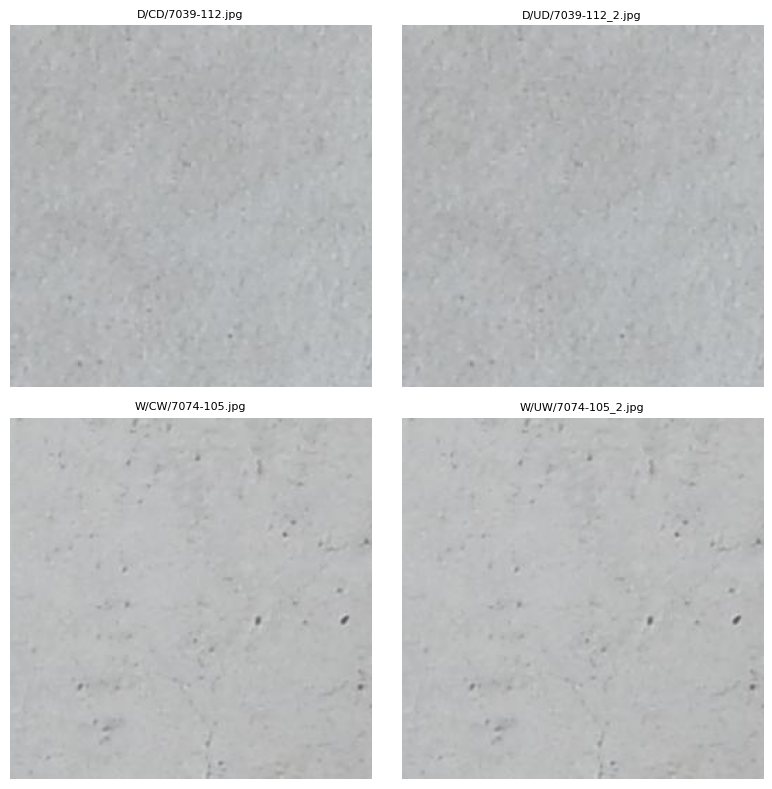

In [ ]:
import zipfile, io
import matplotlib.pyplot as plt
from PIL import Image

outer_path = "/content/drive/MyDrive/Infrascan_Datasets/DATA_Maguire_20180517_ALL.zip"
pairs = [
    ("D/CD/7039-112.jpg", "D/UD/7039-112_2.jpg"),
    ("W/CW/7074-105.jpg", "W/UW/7074-105_2.jpg"),
]

with zipfile.ZipFile(outer_path) as outer:
    inner_name = [n for n in outer.namelist() if n.lower().endswith(".zip")][0]
    with outer.open(inner_name) as f, zipfile.ZipFile(f) as inner:
        fig, axes = plt.subplots(2, 2, figsize=(8, 8))
        for r, pair in enumerate(pairs):
            for c, name in enumerate(pair):
                img = Image.open(io.BytesIO(inner.read(name))).convert("RGB")
                print(name, "size:", img.size)
                axes[r][c].imshow(img)
                axes[r][c].set_title(name, fontsize=8)
                axes[r][c].axis("off")
plt.tight_layout()
plt.show()

In each pair the two files show the same image, yet one copy is labelled cracked and the other uncracked. At least one of the two labels must be wrong, so both copies of each pair are excluded in Section 7.

### 6.3 Extraction to local storage

Checks that the runtime has enough free disk space, then extracts the inner SDNET2018 archive to `/content/sdnet2018_raw`. The extraction first tests the archive checksums, writes to a temporary `.partial` folder, compares the file counts and total size with the values found in Section 5, and renames the folder only if everything matches.

In [ ]:
import shutil
total, used, free = shutil.disk_usage("/content")
print(f"free space on /content: {free/1e9:.1f} GB (need about 1 GB)")
assert free > 2e9, "not enough free disk space"

free space on /content: 120.5 GB (need about 1 GB)


In [ ]:
import zipfile, os, time, collections, sys

outer_path = "/content/drive/MyDrive/Infrascan_Datasets/DATA_Maguire_20180517_ALL.zip"
target  = "/content/sdnet2018_raw"
partial = target + ".partial"

# expected numbers from our earlier checks
expected_counts = {"D/CD": 2025, "D/UD": 11595, "P/CP": 2608,
                   "P/UP": 21726, "W/CW": 3851, "W/UW": 14287}
expected_total_files = 56092
expected_total_bytes = 530772754

print("python:", sys.version.split()[0])
assert os.path.isfile(outer_path), "outer zip missing"
assert not os.path.exists(target),  f"{target} already exists, stopping (nothing overwritten)"
assert not os.path.exists(partial), f"{partial} exists from an earlier try, stopping"

t0 = time.time()
os.makedirs(partial)
with zipfile.ZipFile(outer_path) as outer:
    inner_name = [n for n in outer.namelist() if n.lower().endswith(".zip")][0]
    with outer.open(inner_name) as f, zipfile.ZipFile(f) as inner:
        bad = inner.testzip()          # checks every file's CRC
        assert bad is None, f"corrupt file inside zip: {bad}"
        print("zip CRC test passed, extracting...")
        inner.extractall(partial)
print(f"extracted in {time.time() - t0:.0f} s")

# ---- verify what is on disk ----
counts = collections.Counter()
total_bytes = 0
for cur, dirs, files in os.walk(partial):
    for fn in files:
        rel_dir = os.path.relpath(cur, partial).replace(os.sep, "/")
        counts[rel_dir] += 1
        total_bytes += os.path.getsize(os.path.join(cur, fn))

print("\nfiles per folder (found vs expected):")
for k in sorted(expected_counts):
    print(f"  {k:<6} found {counts.get(k, 0):>7,}   expected {expected_counts[k]:>7,}")
print("total files:", f"{sum(counts.values()):,}", "(expected", f"{expected_total_files:,})")
print("total bytes:", f"{total_bytes:,}", "(expected", f"{expected_total_bytes:,})")

assert dict(counts) == expected_counts, "folder counts do not match"
assert total_bytes == expected_total_bytes, "total size does not match"

os.rename(partial, target)           # only after everything matched
print("\nALL CHECKS PASSED. Data is at:", target)

python: 3.13.16
zip CRC test passed, extracting...
extracted in 20 s

files per folder (found vs expected):
  D/CD   found   2,025   expected   2,025
  D/UD   found  11,595   expected  11,595
  P/CP   found   2,608   expected   2,608
  P/UP   found  21,726   expected  21,726
  W/CW   found   3,851   expected   3,851
  W/UW   found  14,287   expected  14,287
total files: 56,092 (expected 56,092)
total bytes: 530,772,754 (expected 530,772,754)

ALL CHECKS PASSED. Data is at: /content/sdnet2018_raw


All six folders match the expected file counts, and the total size matches (56,092 files, 530,772,754 bytes).

### 6.4 Image integrity

Opens and fully decodes every extracted image to detect truncated or unreadable files, and records the image size, colour mode and format.

In [ ]:
import os, time, collections
from PIL import Image

root = "/content/sdnet2018_raw"
assert os.path.isdir(root), "raw folder missing"

sizes, modes, formats = collections.Counter(), collections.Counter(), collections.Counter()
failed, checked = [], 0
t0 = time.time()

for cur, dirs, files in os.walk(root):
    for fn in files:
        path = os.path.join(cur, fn)
        try:
            with Image.open(path) as im:
                sizes[im.size] += 1
                modes[im.mode] += 1
                formats[im.format] += 1
                im.load()              # fully decode, catches truncated files
            checked += 1
        except Exception as e:
            failed.append((path, repr(e)))

print(f"checked OK : {checked:,}   failed: {len(failed)}   time: {time.time()-t0:.0f} s")
print("image sizes :", dict(sizes.most_common(5)))
print("color modes :", dict(modes))
print("formats     :", dict(formats))
for p, e in failed[:10]:
    print("  FAILED:", p, e)
assert checked + len(failed) == 56092, "count mismatch"

checked OK : 56,092   failed: 0   time: 31 s
image sizes : {(256, 256): 56092}
color modes : {'RGB': 56092}
formats     : {'JPEG': 56092}


All 56,092 images decode correctly and are 256 x 256 px RGB JPEG files. No resizing or colour conversion is needed apart from the 224 x 224 px input size used for ResNet18 later.

### 6.5 Visual inspection

Shows five randomly chosen images (seed 42) from each of the six folders. Files with a `_2` suffix are skipped.

D/CD: ['7033-188.jpg', '7006-77.jpg', '7002-28.jpg', '7039-185.jpg', '7015-147.jpg']
D/UD: ['7019-51.jpg', '7018-136.jpg', '7011-81.jpg', '7008-49.jpg', '7053-66.jpg']
P/CP: ['093-99.jpg', '017-105.jpg', '100-147.jpg', '074-59.jpg', '006-131.jpg']
P/UP: ['005-229.jpg', '015-23.jpg', '035-129.jpg', '037-158.jpg', '079-39.jpg']
W/CW: ['7109-137.jpg', '7070-116.jpg', '7101-244.jpg', '7081-16.jpg', '7118-143.jpg']
W/UW: ['7124-191.jpg', '7128-37.jpg', '7115-42.jpg', '7105-64.jpg', '7090-204.jpg']


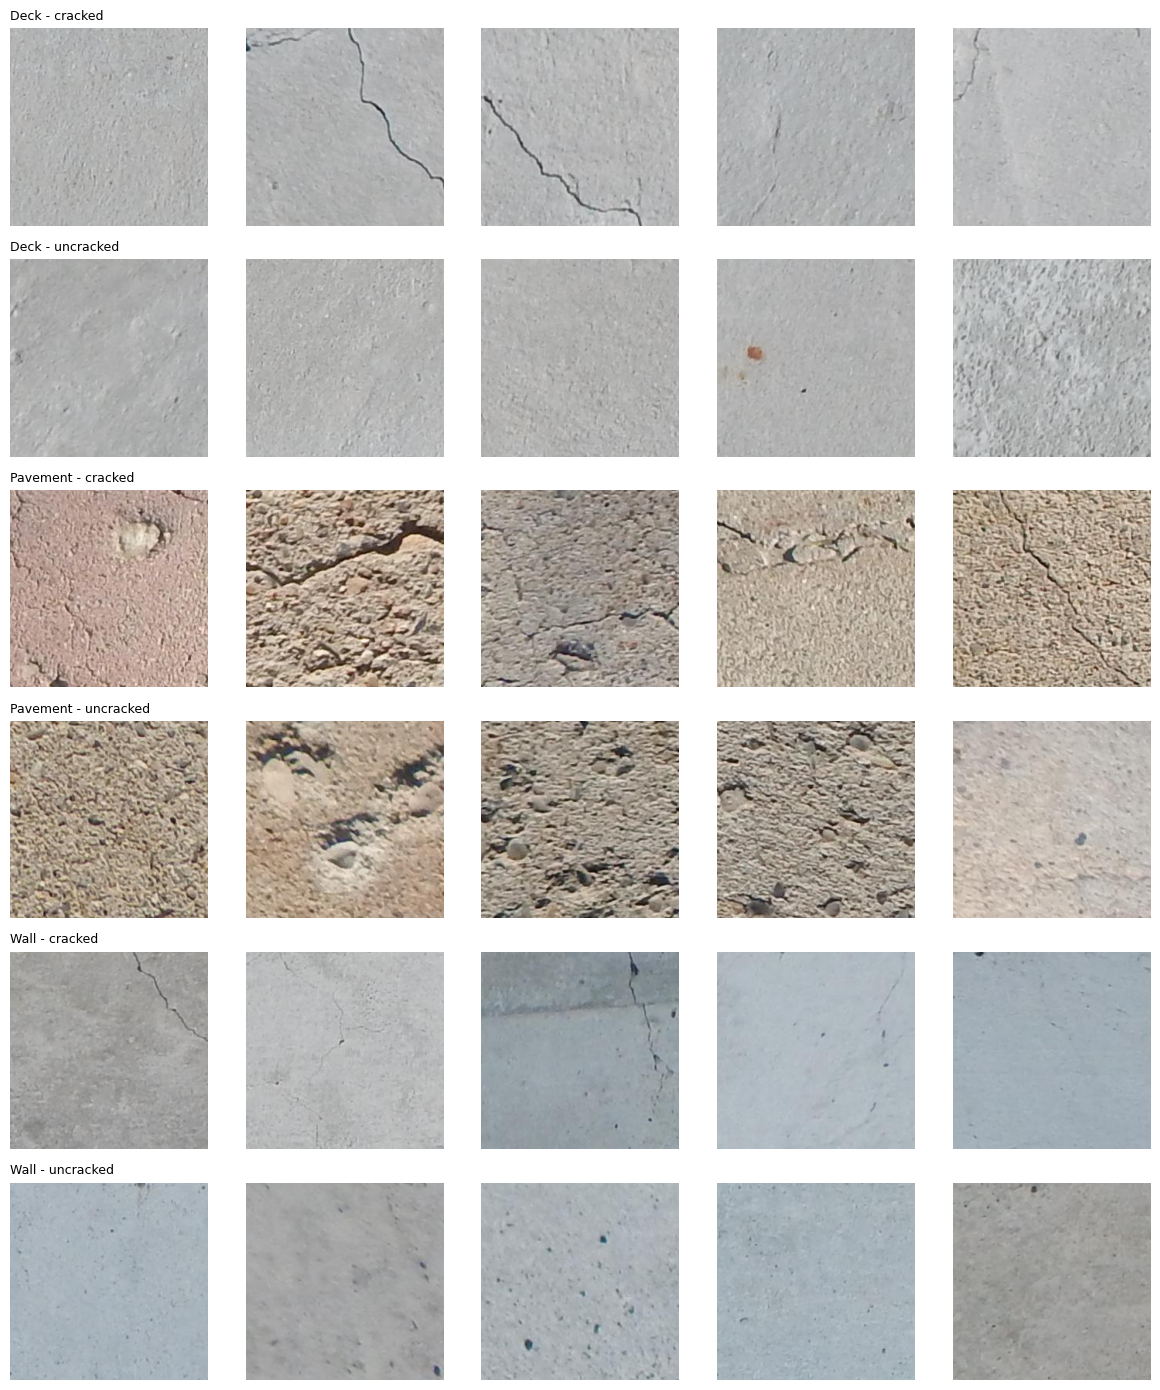

In [ ]:
import os, random
import matplotlib.pyplot as plt
from PIL import Image

root = "/content/sdnet2018_raw"
rng = random.Random(42)
rows = [("D/CD", "Deck - cracked"), ("D/UD", "Deck - uncracked"),
        ("P/CP", "Pavement - cracked"), ("P/UP", "Pavement - uncracked"),
        ("W/CW", "Wall - cracked"), ("W/UW", "Wall - uncracked")]
n_cols = 5

fig, axes = plt.subplots(len(rows), n_cols, figsize=(12, 14))
for r, (folder, title) in enumerate(rows):
    files = sorted(f for f in os.listdir(os.path.join(root, folder)) if "_" not in f)  # skip the _2 files
    picks = rng.sample(files, n_cols)
    print(f"{folder}: {picks}")
    for c, fn in enumerate(picks):
        ax = axes[r][c]
        ax.imshow(Image.open(os.path.join(root, folder, fn)).convert("RGB"))
        ax.axis("off")
        if c == 0:
            ax.set_title(title, fontsize=9, loc="left")
plt.tight_layout()
plt.show()

In most cracked samples a crack is visible as a thin dark line; in some, for example the first deck sample, it is faint or hard to see at this size. Pavement surfaces have a rough, stony texture with dark spots that can resemble cracks, so pavements are likely to be harder to classify than decks or walls.

## 7. Data Cleaning and Metadata Preparation

Builds one table row per image (path, surface, label, photograph number, patch number) and applies the cleaning decisions from Section 6. The 11 exact `_2` duplicates and the 4 files of the two conflicting pairs are excluded, 15 files in total. The 37 `_2` files without a duplicate are kept. Images are also grouped by photograph (`group` is the surface plus the photograph number); the grouping is used for the split in Section 8.

In [ ]:
import os, re, collections
import pandas as pd

root = "/content/sdnet2018_raw"
pat = re.compile(r"^(\d+)-(\d+)(?:_(\d+))?\.jpg$", re.IGNORECASE)

# approved decisions, kept in memory only
conflicts = {"D/CD/7039-112.jpg", "D/UD/7039-112_2.jpg",
             "W/CW/7074-105.jpg", "W/UW/7074-105_2.jpg"}
dup_skip = {f"D/CD/7039-{n}_2.jpg" for n in (110, 111, 113)} | \
           {f"D/UD/7053-{n}_2.jpg" for n in (17, 18, 35, 36, 53, 54, 89, 90)}
assert len(conflicts) == 4 and len(dup_skip) == 11

rows = []
for folder in ["D/CD", "D/UD", "P/CP", "P/UP", "W/CW", "W/UW"]:
    for fn in os.listdir(os.path.join(root, folder)):
        m = pat.match(fn)
        assert m, f"unexpected name: {folder}/{fn}"
        rel = f"{folder}/{fn}"
        rows.append(dict(path=rel, surface=folder[0], label=1 if folder[2] == "C" else 0,
                         photo=m.group(1), patch=int(m.group(2)),
                         is_copy=m.group(3) is not None, excluded=(rel in conflicts or rel in dup_skip)))

df = pd.DataFrame(rows)
print("all files          :", f"{len(df):,}")
print("excluded (approved):", int(df.excluded.sum()), "(expected 15)")
df = df[~df.excluded].copy()
print("kept               :", f"{len(df):,}", "(expected 56,077)")
assert len(df) == 56077

df["group"] = df.surface + "_" + df.photo          # group = surface + photo number
print("\nkept per surface and label:")
print(df.groupby(["surface", "label"]).size().unstack())

g = df.groupby("group").agg(surface=("surface", "first"), n=("label", "size"), cracked=("label", "sum"))
print("\nnumber of groups (photos):", len(g), "   per surface:", g.surface.value_counts().to_dict())
print("\npatches per photo, by surface:")
print(g.groupby("surface").n.describe()[["min", "25%", "50%", "75%", "max"]])
print("\nphotos with 0 cracked patches :", int((g.cracked == 0).sum()))
print("photos with ALL cracked        :", int((g.cracked == g.n).sum()))
g["frac"] = g.cracked / g.n
print("\ncracked fraction per photo, by surface:")
print(g.groupby("surface").frac.describe()[["min", "25%", "50%", "75%", "max"]].round(3))

top = g.sort_values("cracked", ascending=False).head(10)
print("\n10 photos with the most cracked patches:")
print(top[["surface", "n", "cracked"]])
print("share of ALL cracked patches in these 10 photos:", f"{top.cracked.sum() / df.label.sum():.1%}")

all files          : 56,092
excluded (approved): 15 (expected 15)
kept               : 56,077 (expected 56,077)

kept per surface and label:
label        0     1
surface             
D        11586  2021
P        21726  2608
W        14286  3850

number of groups (photos): 230    per surface: {'P': 104, 'W': 72, 'D': 54}

patches per photo, by surface:
           min    25%    50%    75%    max
surface                                   
D        251.0  252.0  252.0  252.0  252.0
P        232.0  234.0  234.0  234.0  234.0
W        246.0  252.0  252.0  252.0  252.0

photos with 0 cracked patches : 5
photos with ALL cracked        : 0

cracked fraction per photo, by surface:
           min    25%    50%    75%    max
surface                                   
D        0.012  0.091  0.135  0.194  0.329
P        0.000  0.085  0.098  0.120  0.261
W        0.067  0.095  0.159  0.299  0.603

10 photos with the most cracked patches:
       surface    n  cracked
group                       
W_70

After cleaning, 56,077 images remain, of which 8,479 (15.1%) are cracked and 47,598 are uncracked. The cracked share differs by surface: about 14.9% for decks, 10.7% for pavements and 21.2% for walls. The 230 photographs contribute between 232 and 252 patches each. Five photographs contain no cracked patch, and none is entirely cracked. The ten photographs with the most cracked patches are all wall photographs and hold 14.3% of all cracked patches.

Patches from one photograph share lighting, texture and background, so they are not independent samples. A random split at patch level would place near-identical images in both training and test data and overstate the accuracy. Section 8 avoids this.

## 8. Dataset Splitting and Validation

The goal is a 70% / 15% / 15% split into training, validation and test sets in which (1) photographs, and photographs taken next to each other, are not divided between sets, and (2) each set has a similar share of cracked images and of each surface type.

The split was developed in three steps. Steps 1 and 2 are kept because they document why the final method was needed and because later cells reuse their variables. **The final split is the one produced in Section 8.4 and saved in Section 8.5.**

### 8.1 Step 1: split by photograph

Uses `StratifiedGroupKFold` with 20 folds (seed 42). All patches of a photograph go to the same fold, and the folds are stratified by surface and class. Three folds become the test set, three the validation set and fourteen the training set.

In [ ]:
import numpy as np, sklearn, random
from sklearn.model_selection import StratifiedGroupKFold

assert "df" in globals() and len(df) == 56077 and "group" in df.columns, "run the previous cell first"
print("sklearn:", sklearn.__version__, "  numpy:", np.__version__)

d = df.reset_index(drop=True).copy()
strata = d.surface + d.label.astype(str)            # 6 strata: surface x label

sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=42)
fold = np.full(len(d), -1)
for k, (_, idx) in enumerate(sgkf.split(d, strata, groups=d.group)):
    fold[idx] = k
assert (fold >= 0).all(), "some rows got no fold"

order = list(range(20))
random.Random(42).shuffle(order)
role = {k: ("test" if i < 3 else "val" if i < 6 else "train") for i, k in enumerate(order)}
d["split"] = [role[k] for k in fold]

# ---- checks ----
assert d.groupby("group").split.nunique().max() == 1, "a photo is in more than one split!"
assert len(d) == 56077
print("OK: every photo is in exactly one split\n")

s = d.groupby("split").agg(images=("label", "size"), cracked=("label", "sum"), photos=("group", "nunique"))
s["% of images"] = (100 * s.images / len(d)).round(1)
s["% cracked"]   = (100 * s.cracked / s.images).round(1)
print(s.loc[["train", "val", "test"]])

print("\nimages / % cracked / photos, per surface and split:")
t = d.groupby(["surface", "split"]).agg(images=("label", "size"), pct_cracked=("label", "mean"), photos=("group", "nunique"))
t["pct_cracked"] = (100 * t.pct_cracked).round(1)
print(t.reindex(["train", "val", "test"], level=1))

zero = d.groupby("group").label.sum()
zero = zero[zero == 0].index
print("\nthe 5 photos with no cracks ->", d[d.group.isin(zero)].groupby("group").split.first().to_dict())

sklearn: 1.6.1   numpy: 2.4.6
OK: every photo is in exactly one split

       images  cracked  photos  % of images  % cracked
split                                                 
train   39251     5994     161         70.0       15.3
val      8297     1232      34         14.8       14.8
test     8529     1253      35         15.2       14.7

images / % cracked / photos, per surface and split:
               images  pct_cracked  photos
surface split                             
D       train   10836         14.5      43
        val      1259         17.4       5
        test     1512         15.2       6
P       train   17082         10.8      73
        val      3510         10.1      15
        test     3742         10.7      16
W       train   11333         22.7      45
        val      3528         18.7      14
        test     3275         19.0      13

the 5 photos with no cracks -> {'P_015': 'train', 'P_016': 'train', 'P_024': 'train', 'P_025': 'train', 'P_097': 'train'}


Every photograph is in exactly one split, the proportions are close to 70/15/15, and each split has between 14.7% and 15.3% cracked images. The next three cells check whether grouping by photograph alone is sufficient.

### 8.2 Do neighbouring photographs resemble each other?

Photographs have consecutive numbers. If photographs with neighbouring numbers show adjacent areas of the same structure, they may resemble each other even though they are different photographs. The share of cracked patches per photograph is used as a simple measure of similarity.

**Neighbouring pairs and their split assignment.** For each surface, counts the pairs of consecutive photograph numbers that fall into different splits and computes the correlation of the cracked share between neighbouring photographs. The T/V/E string shows the split of each photograph in numerical order (T = train, V = validation, E = test).

In [ ]:
import numpy as np
assert "d" in globals() and "split" in d.columns, "run the split cell first"

g = d.groupby("group").agg(surface=("surface", "first"),
                           photo=("photo", lambda s: int(s.iloc[0])),
                           n=("label", "size"), cracked=("label", "sum"),
                           split=("split", "first")).reset_index()
g["frac"] = g.cracked / g.n

for s in ["D", "P", "W"]:
    x = g[g.surface == s].sort_values("photo").reset_index(drop=True)
    p, sp, fr = x.photo.values, x.split.values, x.frac.values
    consec = np.where(np.diff(p) == 1)[0]          # pairs with photo numbers n, n+1
    cross = sum(sp[i] != sp[i + 1] for i in consec)
    print(f"\n=== surface {s}: {len(x)} photos, numbers {p.min()}..{p.max()} ===")
    print("consecutive-number pairs:", len(consec), "| of these in DIFFERENT splits:", cross)
    if len(consec) > 2:
        a, b = fr[consec], fr[consec + 1]
        print("correlation of cracked-fraction between neighbours:", round(float(np.corrcoef(a, b)[0, 1]), 3))
    print("split order (T=train, V=val, E=test):")
    print("".join({"train": "T", "val": "V", "test": "E"}[v] for v in sp))


=== surface D: 54 photos, numbers 7001..7057 ===
consecutive-number pairs: 51 | of these in DIFFERENT splits: 13
correlation of cracked-fraction between neighbours: 0.49
split order (T=train, V=val, E=test):
TTTTVEVTEETTTETTTTTTTTTTTTTTTETTTTTTVVVETTTTTTTTTTTTTT

=== surface P: 104 photos, numbers 1..104 ===
consecutive-number pairs: 103 | of these in DIFFERENT splits: 50
correlation of cracked-fraction between neighbours: 0.396
split order (T=train, V=val, E=test):
ETTTTTVVTTETTVTTETTETTTTTTETTTTVTVETTTVETTTTETTTTETVVTTTTVTVTETTETTTTTTTTVTETTTETTTTTTTVEVETTTVETTTTTTTV

=== surface W: 72 photos, numbers 7069..7140 ===
consecutive-number pairs: 71 | of these in DIFFERENT splits: 42
correlation of cracked-fraction between neighbours: 0.602
split order (T=train, V=val, E=test):
TETTTETTTTETTVVTETTVTTTTTVTTTTVEVTTVTVTEVETVEVTTTEETVTTVTTTTTETTEETVTTTT


Neighbouring photographs are positively correlated (0.49 for decks, 0.40 for pavements and 0.60 for walls), and 105 of the 225 neighbouring pairs were placed in different splits.

**Correlation at larger distances.** Repeats the correlation for photographs that are 1 to 30 numbers apart (the lag).

In [ ]:
import numpy as np
assert "d" in globals() and "split" in d.columns, "run the split cell first"

g = d.groupby("group").agg(surface=("surface", "first"),
                           photo=("photo", lambda s: int(s.iloc[0])),
                           n=("label", "size"), cracked=("label", "sum")).reset_index()
g["frac"] = g.cracked / g.n

lags = [1, 2, 3, 4, 5, 6, 8, 10, 20, 30]
print("correlation of cracked-fraction between photos that are `lag` numbers apart")
print("(pairs = how many photo pairs were used; lag 20-30 is our 'far apart' baseline)\n")
print(f"{'surface':8}{'lag':>5}{'pairs':>7}{'corr':>8}")
for s in ["D", "P", "W"]:
    x = g[g.surface == s]
    fr = dict(zip(x.photo, x.frac))
    for L in lags:
        a = [fr[p] for p in fr if (p + L) in fr]
        b = [fr[p + L] for p in fr if (p + L) in fr]
        c = float(np.corrcoef(a, b)[0, 1]) if len(a) > 5 else float("nan")
        print(f"{s:8}{L:>5}{len(a):>7}{c:>8.3f}")
    print()

correlation of cracked-fraction between photos that are `lag` numbers apart
(pairs = how many photo pairs were used; lag 20-30 is our 'far apart' baseline)

surface   lag  pairs    corr
D           1     51   0.490
D           2     50   0.041
D           3     50  -0.169
D           4     49  -0.388
D           5     48  -0.280
D           6     47  -0.067
D           8     45   0.009
D          10     43   0.135
D          20     34   0.217
D          30     24   0.022

P           1    103   0.396
P           2    102   0.004
P           3    101  -0.150
P           4    100  -0.188
P           5     99  -0.071
P           6     98  -0.003
P           8     96   0.084
P          10     94   0.073
P          20     84   0.004
P          30     74   0.115

W           1     71   0.602
W           2     70   0.576
W           3     69   0.517
W           4     68   0.391
W           5     67   0.291
W           6     66   0.308
W           8     64   0.054
W          10     62  -0.049


The correlation is clearly positive at lag 1 for all surfaces. For decks and pavements it falls to about zero at lag 2 (and is negative at some larger lags). For walls it stays above 0.5 up to lag 3, is still about 0.3 at lags 5 and 6, and is close to zero from lag 8. Values at large lags rest on fewer pairs and fluctuate.

**Odd and even starting numbers.** Splits the lag-1 pairs by whether the first photograph number is odd or even, to check whether the correlation is concentrated in particular pairs.

In [ ]:
import numpy as np
assert "d" in globals() and "split" in d.columns, "run the split cell first"

g = d.groupby("group").agg(surface=("surface", "first"),
                           photo=("photo", lambda s: int(s.iloc[0])),
                           n=("label", "size"), cracked=("label", "sum")).reset_index()
g["frac"] = g.cracked / g.n

print("lag-1 correlation, split by whether the FIRST photo number of the pair is odd or even\n")
print(f"{'surface':8}{'first no.':>10}{'pairs':>7}{'corr':>8}")
for s in ["D", "P", "W"]:
    x = g[g.surface == s]
    fr = dict(zip(x.photo, x.frac))
    for par, name in [(1, "odd"), (0, "even")]:
        ps = [p for p in fr if (p + 1) in fr and p % 2 == par]
        a = [fr[p] for p in ps]; b = [fr[p + 1] for p in ps]
        c = float(np.corrcoef(a, b)[0, 1]) if len(ps) > 5 else float("nan")
        print(f"{s:8}{name:>10}{len(ps):>7}{c:>8.3f}")
    print()

lag-1 correlation, split by whether the FIRST photo number of the pair is odd or even

surface  first no.  pairs    corr
D              odd     26   0.250
D             even     25   0.746

P              odd     52   0.426
P             even     51   0.402

W              odd     36   0.619
W             even     35   0.594



For decks the correlation is much stronger when the first number is even (0.75 against 0.25), which points to related photographs forming pairs. For pavements and walls the two groups are similar. Overall, neighbouring photographs are related, most strongly on walls, so the next step groups neighbouring photographs into blocks.

### 8.3 Step 2: split by block of neighbouring photographs

Neighbouring photographs are grouped into blocks: pairs of photographs for decks and pavements and groups of four for walls, following the correlation pattern above. A block is never divided. The same method and seed as in Step 1 are used (`StratifiedGroupKFold`, 20 folds, seed 42).

In [ ]:
import numpy as np, random, sklearn
from sklearn.model_selection import StratifiedGroupKFold

assert "d" in globals() and len(d) == 56077 and "split" in d.columns, "run the earlier cells first"
print("sklearn:", sklearn.__version__, "  numpy:", np.__version__)

d2 = d.reset_index(drop=True).copy()
d2["split_old"] = d2["split"]
d2 = d2.drop(columns="split")
d2["photo_no"] = d2.photo.astype(int)

# photo-number ranges seen in the data (fail loudly if they differ)
rng = d2.groupby("surface").photo_no.agg(["min", "max"])
assert rng.loc["D"].tolist() == [7001, 7057] and rng.loc["P"].tolist() == [1, 104] \
       and rng.loc["W"].tolist() == [7069, 7140], f"unexpected photo ranges:\n{rng}"

def block(s, p):
    if s == "D": return (p - 7000) // 2     # 7001 | 7002+7003 | 7004+7005 ...
    if s == "P": return (p - 1) // 2        # 1+2 | 3+4 | ...
    if s == "W": return (p - 7069) // 4     # 7069-7072 | 7073-7076 | ...
    raise ValueError(s)

d2["block"] = [block(s, p) for s, p in zip(d2.surface, d2.photo_no)]
assert d2.block.min() >= 0
d2["bgroup"] = d2.surface + "_B" + d2.block.astype(str)

bg = d2.groupby("bgroup").agg(surface=("surface", "first"), photos=("group", "nunique"))
print("\nblocks per surface:", bg.surface.value_counts().to_dict(), "| total blocks:", len(bg))
print("photos per block (min/max):", int(bg.photos.min()), "/", int(bg.photos.max()))

# ---- split: same method, same seed, same role assignment as before ----
strata = d2.surface + d2.label.astype(str)
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=42)
fold = np.full(len(d2), -1)
for k, (_, idx) in enumerate(sgkf.split(d2, strata, groups=d2.bgroup)):
    fold[idx] = k
assert (fold >= 0).all()

order = list(range(20))
random.Random(42).shuffle(order)
role = {k: ("test" if i < 3 else "val" if i < 6 else "train") for i, k in enumerate(order)}
d2["split"] = [role[k] for k in fold]

# ---- checks ----
assert d2.groupby("bgroup").split.nunique().max() == 1, "a block is in more than one split!"
assert d2.groupby("group").split.nunique().max() == 1, "a photo is in more than one split!"
assert len(d2) == 56077 and d2.label.sum() == 8479
print("OK: every block and every photo is in exactly one split\n")

s = d2.groupby("split").agg(images=("label", "size"), cracked=("label", "sum"),
                            photos=("group", "nunique"), blocks=("bgroup", "nunique"))
s["% of images"] = (100 * s.images / len(d2)).round(1)
s["% cracked"] = (100 * s.cracked / s.images).round(1)
print(s.loc[["train", "val", "test"]])

print("\nper surface and split:")
t = d2.groupby(["surface", "split"]).agg(images=("label", "size"), pct_cracked=("label", "mean"),
                                         photos=("group", "nunique"), blocks=("bgroup", "nunique"))
t["pct_cracked"] = (100 * t.pct_cracked).round(1)
print(t.reindex(["train", "val", "test"], level=1))

# ---- neighbour check ----
g = d2.groupby("group").agg(surface=("surface", "first"), photo=("photo_no", "first"),
                            bgroup=("bgroup", "first"), split=("split", "first")).reset_index()
print("\nconsecutive photo pairs in DIFFERENT splits (was 105 of 225 before):")
tot_cross = tot_pairs = 0
for sf in ["D", "P", "W"]:
    x = g[g.surface == sf].sort_values("photo").reset_index(drop=True)
    i = np.where(np.diff(x.photo.values) == 1)[0]
    cross = [j for j in i if x.split[j] != x.split[j + 1]]
    same_block_cross = [j for j in cross if x.bgroup[j] == x.bgroup[j + 1]]
    assert len(same_block_cross) == 0
    tot_cross += len(cross); tot_pairs += len(i)
    print(f"  {sf}: {len(cross)} of {len(i)}")
print(f"  total: {tot_cross} of {tot_pairs}")

zero = d2.groupby("group").label.sum()
zero = zero[zero == 0].index
print("\nthe 5 zero-crack photos ->", d2[d2.group.isin(zero)].groupby("group").split.first().to_dict())
print("images whose split changed vs old split:",
      f"{(d2.split != d2.split_old).mean():.1%}")

sklearn: 1.6.1   numpy: 2.4.6

blocks per surface: {'P': 52, 'D': 29, 'W': 18} | total blocks: 99
photos per block (min/max): 1 / 4
OK: every block and every photo is in exactly one split

       images  cracked  photos  blocks  % of images  % cracked
split                                                         
train   39591     5682     163      69         70.6       14.4
val      8352     1540      34      15         14.9       18.4
test     8134     1257      33      15         14.5       15.5

per surface and split:
               images  pct_cracked  photos  blocks
surface split                                     
D       train    6300         13.0      25      14
        val      3528         17.0      14       7
        test     3779         16.0      15       8
P       train   19186         11.1      82      41
        val      2808          8.8      12       6
        test     2340          9.7      10       5
W       train   14105         19.4      56      14
        val  

There are 99 blocks (29 deck, 52 pavement and 18 wall blocks). Blocks are never divided, and the number of neighbouring pairs separated across sets falls from 105 to 46 of 225. The block split is, however, less balanced than Step 1: the validation set has 18.4% cracked images against 14.4% in the training set, and it contains only two wall blocks (34.4% cracked). Step 3 balances the sets.

### 8.4 Step 3 (final): balanced assignment of blocks

For each surface, 20,000 random orderings of its blocks are generated (seed 42). In each ordering the blocks are assigned to training, validation or test according to their position (first 70% of the images, next 15%, last 15%). A score measures how far the image shares and the cracked rates of the three sets are from their targets, and the ordering with the lowest score is used. Blocks are never divided.

In [ ]:
import numpy as np
assert "d2" in globals() and "bgroup" in d2.columns and len(d2) == 56077, "run the previous cell first"

d3 = d2.copy()
d3["split_v2"] = d3["split"]            # keep the block-based result for comparison
names = np.array(["train", "val", "test"])
target = np.array([0.70, 0.15, 0.15])
N_TRIALS = 20000
rs = np.random.RandomState(42)

assign = {}
for sf in ["D", "P", "W"]:
    b = d3[d3.surface == sf].groupby("bgroup").agg(n=("label", "size"), c=("label", "sum")).reset_index()
    n = b.n.values.astype(float); c = b.c.values.astype(float)
    T = n.sum(); rate = c.sum() / T
    best_loss, best_perm, best_lab = np.inf, None, None
    for _ in range(N_TRIALS):
        perm = rs.permutation(len(b))
        mid = (np.cumsum(n[perm]) - n[perm] / 2) / T
        lab = np.where(mid < 0.70, 0, np.where(mid < 0.85, 1, 2))
        imgs = np.bincount(lab, weights=n[perm], minlength=3)
        if (imgs == 0).any():
            continue
        cr = np.bincount(lab, weights=c[perm], minlength=3)
        loss = (((imgs / T - target) / 0.02) ** 2).sum() + (((cr / imgs - rate) / 0.02) ** 2).sum()
        if loss < best_loss:
            best_loss, best_perm, best_lab = loss, perm.copy(), lab.copy()
    assert best_perm is not None
    for i, pos in enumerate(best_perm):
        assign[b.bgroup[pos]] = names[best_lab[i]]
    print(f"surface {sf}: {len(b)} blocks, best score {best_loss:.2f} (lower = better), trials {N_TRIALS}")

d3["split"] = d3.bgroup.map(assign)
assert d3.split.notna().all()
assert d3.groupby("bgroup").split.nunique().max() == 1
assert d3.groupby("group").split.nunique().max() == 1
assert len(d3) == 56077 and d3.label.sum() == 8479
print("\nOK: every block and every photo is in exactly one split\n")

s = d3.groupby("split").agg(images=("label", "size"), cracked=("label", "sum"),
                            photos=("group", "nunique"), blocks=("bgroup", "nunique"))
s["% of images"] = (100 * s.images / len(d3)).round(1)
s["% cracked"] = (100 * s.cracked / s.images).round(1)
print(s.loc[["train", "val", "test"]])

print("\nper surface and split (overall surface cracked rate: D 14.9, P 10.7, W 21.2):")
t = d3.groupby(["surface", "split"]).agg(images=("label", "size"), pct_cracked=("label", "mean"),
                                         photos=("group", "nunique"), blocks=("bgroup", "nunique"))
t["pct_images_of_surface"] = (100 * t.images / t.groupby(level=0).images.transform("sum")).round(1)
t["pct_cracked"] = (100 * t.pct_cracked).round(1)
print(t.reindex(["train", "val", "test"], level=1))

g = d3.groupby("group").agg(surface=("surface", "first"), photo=("photo_no", "first"),
                            split=("split", "first")).reset_index()
print("\nconsecutive photo pairs in DIFFERENT splits (block split: 46 of 225):")
tot = 0
for sf in ["D", "P", "W"]:
    x = g[g.surface == sf].sort_values("photo").reset_index(drop=True)
    i = np.where(np.diff(x.photo.values) == 1)[0]
    cross = sum(x.split[j] != x.split[j + 1] for j in i)
    tot += cross
    print(f"  {sf}: {cross} of {len(i)}")
print(f"  total: {tot} of 225")

zero = d3.groupby("group").label.sum()
zero = zero[zero == 0].index
print("\nthe 5 zero-crack photos ->", d3[d3.group.isin(zero)].groupby("group").split.first().to_dict())

surface D: 29 blocks, best score 0.05 (lower = better), trials 20000
surface P: 52 blocks, best score 0.22 (lower = better), trials 20000
surface W: 18 blocks, best score 5.72 (lower = better), trials 20000

OK: every block and every photo is in exactly one split

       images  cracked  photos  blocks  % of images  % cracked
split                                                         
train   39519     5999     162      69         70.5       15.2
val      7774     1133      32      15         13.9       14.6
test     8784     1347      36      15         15.7       15.3

per surface and split (overall surface cracked rate: D 14.9, P 10.7, W 21.2):
               images  pct_cracked  photos  blocks  pct_images_of_surface
surface split                                                            
D       train    9575         14.9      38      20                   70.4
        val      2016         14.8       8       5                   14.8
        test     2016         14.9       8   

The final split has 39,519 training, 7,774 validation and 8,784 test images (70.5%, 13.9% and 15.7%) with 15.2%, 14.6% and 15.3% cracked images respectively. Each surface appears in all three sets with nearly the same cracked rate as in the whole surface (see the per-surface table above). Only 39 of 225 neighbouring photograph pairs lie in different sets, and these pairs fall on block boundaries.

The final scores per surface are 0.05 for decks, 0.22 for pavements and 5.72 for walls (lower is better). Walls are the least balanced, which is expected with only 18 blocks of four photographs: the wall validation set holds 11.1% of the wall images, against 14.8% for decks and 15.4% for pavements.

### 8.5 Saving the split

Writes the final split to `split_v1.csv` with the columns `path`, `label`, `surface`, `photo`, `block` and `split`. The cell refuses to overwrite an existing file, reads the file back and compares it with the data in memory, checks again that no photograph or block is divided, and records a SHA-256 checksum so that later sessions can verify that the split has not changed.

In [ ]:
import os, hashlib, sys
import numpy as np, pandas as pd, sklearn

assert "d3" in globals() and len(d3) == 56077, "d3 missing: run the earlier cells first"
assert d3.label.sum() == 8479
assert d3.groupby("bgroup").split.nunique().max() == 1
assert d3.groupby("group").split.nunique().max() == 1
assert set(d3.split.unique()) == {"train", "val", "test"}

out_dir = "/content/drive/MyDrive/InfraScan/classification/outputs"
out_path = os.path.join(out_dir, "split_v1.csv")
assert os.path.ismount("/content/drive"), "Drive not mounted"
assert not os.path.exists(out_path), f"{out_path} already exists: NOT overwriting"

# the 'block' column holds the block id with the surface prefix (e.g. W_B3), so it is unique across surfaces
out = pd.DataFrame({
    "path": d3.path.astype(str),
    "label": d3.label.astype(int),
    "surface": d3.surface.astype(str),
    "photo": d3.photo.astype(str),          # kept as text: pavement photo numbers have leading zeros
    "block": d3.bgroup.astype(str),
    "split": d3.split.astype(str),
}).sort_values("path").reset_index(drop=True)
assert out.path.is_unique and len(out) == 56077

os.makedirs(out_dir, exist_ok=True)
with open(out_path, "x", newline="") as f:      # "x" = fail if the file exists
    out.to_csv(f, index=False, lineterminator="\n")

# ---- read back and verify ----
back = pd.read_csv(out_path, dtype=str, keep_default_na=False)
back["label"] = back.label.astype(int)
assert list(back.columns) == list(out.columns)
assert back.equals(out), "file content differs from memory!"
assert len(back) == 56077 and back.label.sum() == 8479
assert back.groupby("block").split.nunique().max() == 1
assert back.groupby(["surface", "photo"]).split.nunique().max() == 1

sha = hashlib.sha256(open(out_path, "rb").read()).hexdigest()
print("saved      :", out_path)
print("size bytes :", f"{os.path.getsize(out_path):,}")
print("rows       :", f"{len(back):,}", "| cracked:", int(back.label.sum()))
print("SHA-256    :", sha)
print("\nsplit summary (from the file):")
s = back.groupby("split").agg(images=("label", "size"), cracked=("label", "sum"))
s["% cracked"] = (100 * s.cracked / s.images).round(1)
print(s.loc[["train", "val", "test"]])
print("\nversions   : python", sys.version.split()[0], "| sklearn", sklearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__)
print("seed       : 42 (StratifiedGroupKFold fold assignment, shuffle of fold roles, 20,000-trial block search per surface)")

saved      : /content/drive/MyDrive/InfraScan/classification/outputs/split_v1.csv
size bytes : 2,069,737
rows       : 56,077 | cracked: 8479
SHA-256    : 09a990827789889193fb6fb8be45e2910ca643aaba2d9742a127550387581db7

split summary (from the file):
       images  cracked  % cracked
split                            
train   39519     5999       15.2
val      7774     1133       14.6
test     8784     1347       15.3

versions   : python 3.13.16 | sklearn 1.6.1 | numpy 2.4.6 | pandas 2.2.3
seed       : 42 (StratifiedGroupKFold fold assignment, shuffle of fold roles, 20,000-trial block search per surface)


The file contains 56,077 rows, of which 8,479 are cracked. The checksum is verified in the next step.

### 8.6 Verifying the saved split

In a later session, the split file is compared with the stored checksum, and every image listed in it is opened and decoded.

In [ ]:
import os, hashlib, time, collections
import pandas as pd
import PIL
from PIL import Image

csv_path = "/content/drive/MyDrive/InfraScan/classification/outputs/split_v1.csv"
raw_root = "/content/sdnet2018_raw"
EXPECTED_SHA = "09a990827789889193fb6fb8be45e2910ca643aaba2d9742a127550387581db7"

assert os.path.isdir(raw_root), "raw data folder missing (runtime restarted?)"
sha = hashlib.sha256(open(csv_path, "rb").read()).hexdigest()
assert sha == EXPECTED_SHA, f"split file changed! {sha}"
print("split file SHA-256 matches. Pillow:", PIL.__version__)

sp = pd.read_csv(csv_path, dtype=str, keep_default_na=False)
assert len(sp) == 56077
print("images to check:", f"{len(sp):,}")

sizes, modes, formats = collections.Counter(), collections.Counter(), collections.Counter()
missing, broken = [], []
t0 = time.time()
for i, rel in enumerate(sp.path, 1):
    p = os.path.join(raw_root, rel)
    if not os.path.isfile(p):
        missing.append(rel); continue
    try:
        with Image.open(p) as im:
            fmt, size, mode = im.format, im.size, im.mode
            im.load()                      # full decode: catches truncated files
        sizes[size] += 1; modes[mode] += 1; formats[fmt] += 1
    except Exception as e:
        broken.append((rel, repr(e)[:120]))
    if i % 10000 == 0:
        print(f"  checked {i:,} ... {time.time() - t0:.0f}s")

print(f"\ndone in {time.time() - t0:.0f}s")
print("missing files :", len(missing))
print("broken files  :", len(broken))
print("sizes         :", dict(sizes))
print("color modes   :", dict(modes))
print("formats       :", dict(formats))
print("first problems:", (missing[:5], broken[:5]))
assert len(missing) == 0 and len(broken) == 0, "problems found: paste this output, change nothing"
print("\nOK: all", f"{len(sp):,}", "images exist and decode")

split file SHA-256 matches. Pillow: 11.3.0
images to check: 56,077
  checked 10,000 ... 6s
  checked 20,000 ... 12s
  checked 30,000 ... 17s
  checked 40,000 ... 23s
  checked 50,000 ... 27s

done in 30s
missing files : 0
broken files  : 0
sizes         : {(256, 256): 56077}
color modes   : {'RGB': 56077}
formats       : {'JPEG': 56077}
first problems: ([], [])

OK: all 56,077 images exist and decode


The checksum matches, and all 56,077 images exist and decode correctly.

Loads the split file and shows its first rows, the number of images per split and the number of images per class.

In [13]:
import pandas as pd
import os

csv_path = "/content/drive/MyDrive/InfraScan/classification/outputs/split_v1.csv"

df = pd.read_csv(csv_path)

print("Total rows:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nSplit distribution:")
print(df["split"].value_counts())

print("\nLabel distribution:")
print(df["label"].value_counts())

Total rows: 56077

Columns:
['path', 'label', 'surface', 'photo', 'block', 'split']

First 5 rows:


,path,label,surface,photo,block,split
0,D/CD/7001-115.jpg,1,D,7001,D_B0,val
1,D/CD/7001-139.jpg,1,D,7001,D_B0,val
2,D/CD/7001-151.jpg,1,D,7001,D_B0,val
3,D/CD/7001-157.jpg,1,D,7001,D_B0,val
4,D/CD/7001-169.jpg,1,D,7001,D_B0,val



Split distribution:
split
train    39519
test      8784
val       7774
Name: count, dtype: int64

Label distribution:
label
0    47598
1     8479
Name: count, dtype: int64


Checks again that every path in the split file exists in the extracted data, and counts the images per split and class.

In [20]:
import pandas as pd
import os

csv_path = "/content/drive/MyDrive/InfraScan/classification/outputs/split_v1.csv"
image_root = "/content/sdnet2018_raw"

df = pd.read_csv(csv_path)

df["full_path"] = df["path"].apply(
    lambda p: os.path.join(image_root, p)
)

df["exists"] = df["full_path"].apply(os.path.isfile)

print("Total images:", len(df))
print("Existing images:", df["exists"].sum())
print("Missing images:", (~df["exists"]).sum())

print("\nMissing image examples:")
print(df.loc[~df["exists"], "path"].head(10).tolist())

print("\nSplit distribution:")
print(df.groupby(["split", "label"]).size())

Total images: 56077
Existing images: 56077
Missing images: 0

Missing image examples:
[]

Split distribution:
split  label
test   0         7437
       1         1347
train  0        33520
       1         5999
val    0         6641
       1         1133
dtype: int64


**Final split of SDNET2018 (`split_v1.csv`)**

| Split | Images | Cracked | Uncracked | % cracked | Photographs | Blocks |
|---|---|---|---|---|---|---|
| Train | 39,519 | 5,999 | 33,520 | 15.2 | 162 | 69 |
| Validation | 7,774 | 1,133 | 6,641 | 14.6 | 32 | 15 |
| Test | 8,784 | 1,347 | 7,437 | 15.3 | 36 | 15 |
| Total | 56,077 | 8,479 | 47,598 | 15.1 | 230 | 99 |

This split is used unchanged for ResNet18 training, validation and testing in Sections 9 to 11. SDNET2018 comes from 230 photographs taken on one university campus, so the validation and test sets contain only 32 and 36 photographs. This limits how precisely they estimate performance (Section 20).

## 9. Classification Model: ResNet18

### 9.1 What the classifier does

ResNet18 is a convolutional neural network with 18 weight layers. Its residual (skip) connections let each block learn a correction to its input, which makes deep networks easier to train. In InfraScan it receives one image, resized to 224 x 224 px, and produces two scores, one for uncracked and one for cracked. A softmax converts the scores into probabilities, and the larger one gives the predicted class. The classifier decides whether a crack is present. It does not say where the crack is.

The network starts from weights pre-trained on ImageNet (transfer learning), so it already responds to edges, textures and shapes and only has to be adapted to crack images. Its last layer is replaced by a new two-output layer, and all layers are then fine-tuned.

### 9.2 Data pipeline

Defines the dataset class that reads an image path and label from the split file, the image transformations, and the three data loaders (batch size 32). Training images are resized to 224 x 224 px, flipped horizontally at random and normalised with the ImageNet mean and standard deviation, which the pre-trained weights expect. Validation and test images receive the same resizing and normalisation without the random flip.

In [21]:
import os
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Dataset paths
CSV_PATH = "/content/drive/MyDrive/InfraScan/classification/outputs/split_v1.csv"
IMAGE_ROOT = "/content/sdnet2018_raw"

# Read CSV
df = pd.read_csv(CSV_PATH)

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Custom dataset
class CrackDataset(Dataset):
    def __init__(self, dataframe, root, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.root = root
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        image_path = os.path.join(self.root, row["path"])
        image = Image.open(image_path).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

# Separate datasets
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]
test_df = df[df["split"] == "test"]

train_dataset = CrackDataset(
    train_df, IMAGE_ROOT, train_transform
)

val_dataset = CrackDataset(
    val_df, IMAGE_ROOT, eval_transform
)

test_dataset = CrackDataset(
    test_df, IMAGE_ROOT, eval_transform
)

# DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=32,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=32,
    shuffle=False, num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=32,
    shuffle=False, num_workers=2, pin_memory=True
)

# Verify one batch
images, labels = next(iter(train_loader))

print("GPU available:", torch.cuda.is_available())
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in batch:", labels.unique().tolist())

GPU available: True
Train batches: 1235
Validation batches: 243
Test batches: 275
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels in batch: [0, 1]


The loaders contain 1,235 training, 243 validation and 275 test batches. A batch has the shape 32 x 3 x 224 x 224 and contains both classes.

### 9.3 Model, loss function and optimiser

Loads ResNet18 with ImageNet weights, replaces the final layer by a two-class layer and moves the model to the GPU. Training uses the cross-entropy loss (without class weights) and the Adam optimiser with a learning rate of 0.0001.

In [22]:
import torch
import torch.nn as nn
from torchvision import models

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load pretrained ResNet18
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace final layer for 2 classes
model.fc = nn.Linear(model.fc.in_features, 2)

# Move model to GPU
model = model.to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("\nResNet18 model configured successfully!")
print("Number of classes:", model.fc.out_features)
print("Model device:", next(model.parameters()).device)

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 62.6MB/s]



ResNet18 model configured successfully!
Number of classes: 2
Model device: cuda:0


### 9.4 Check of the data setup

Prints the size of each dataset and the training transformation as a final check before training.

In [23]:
# Check DataLoader variables
for name in ["train_loader", "val_loader", "valid_loader", "test_loader"]:
    if name in globals():
        loader = globals()[name]
        print(f"\n{name}:")
        print("Batches:", len(loader))
        print("Dataset size:", len(loader.dataset))
        print("Dataset type:", type(loader.dataset).__name__)

# Check image transformations
if "train_loader" in globals():
    dataset = train_loader.dataset
    print("\nTraining dataset transform:")
    print(getattr(dataset, "transform", "Transform not directly available"))


train_loader:
Batches: 1235
Dataset size: 39519
Dataset type: CrackDataset

val_loader:
Batches: 243
Dataset size: 7774
Dataset type: CrackDataset

test_loader:
Batches: 275
Dataset size: 8784
Dataset type: CrackDataset

Training dataset transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


The dataset sizes (39,519 / 7,774 / 8,784) agree with the split file in Section 8.

## 10. Classification Training

The model is trained for 10 epochs. After each epoch it is evaluated on the validation set, and the checkpoint with the highest validation accuracy is saved to Google Drive (`resnet18_best.pth`) together with the optimiser state and the loss and accuracy history. The test set is not used during training.

In [24]:
import os
import copy
import torch
import torch.nn as nn

# Save checkpoint in Google Drive
save_dir = "/content/drive/MyDrive/InfraScan/classification/checkpoints"
os.makedirs(save_dir, exist_ok=True)

best_model_path = os.path.join(save_dir, "resnet18_best.pth")

num_epochs = 10
best_val_acc = 0.0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(num_epochs):

    # ---------------- TRAINING ----------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # ---------------- VALIDATION ----------------
    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc*100:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_acc*100:.2f}%")

    # Save best validation checkpoint
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_acc": best_val_acc,
            "history": history
        }, best_model_path)

        print("Best model checkpoint saved!")

print("\nTraining completed!")
print("Best validation accuracy:", round(best_val_acc * 100, 2), "%")
print("Checkpoint:", best_model_path)


Epoch [1/10]
Train Loss: 0.2343 | Train Accuracy: 91.51%
Val Loss:   0.2027 | Val Accuracy:   93.08%
Best model checkpoint saved!

Epoch [2/10]
Train Loss: 0.1753 | Train Accuracy: 93.99%
Val Loss:   0.2466 | Val Accuracy:   90.84%

Epoch [3/10]
Train Loss: 0.1530 | Train Accuracy: 94.81%
Val Loss:   0.2034 | Val Accuracy:   93.26%
Best model checkpoint saved!

Epoch [4/10]
Train Loss: 0.1333 | Train Accuracy: 95.51%
Val Loss:   0.2049 | Val Accuracy:   93.23%

Epoch [5/10]
Train Loss: 0.1113 | Train Accuracy: 96.19%
Val Loss:   0.2148 | Val Accuracy:   93.38%
Best model checkpoint saved!

Epoch [6/10]
Train Loss: 0.0935 | Train Accuracy: 96.94%
Val Loss:   0.2734 | Val Accuracy:   91.25%

Epoch [7/10]
Train Loss: 0.0781 | Train Accuracy: 97.38%
Val Loss:   0.2460 | Val Accuracy:   92.26%

Epoch [8/10]
Train Loss: 0.0622 | Train Accuracy: 97.94%
Val Loss:   0.2619 | Val Accuracy:   92.59%

Epoch [9/10]
Train Loss: 0.0551 | Train Accuracy: 98.14%
Val Loss:   0.2677 | Val Accuracy:   92

**Interpretation.** Training accuracy rises steadily from 91.5% to 98.5%, and training loss falls from 0.234 to 0.045. Validation loss does not improve after the first epochs (0.203 in epoch 1 and 0.293 in epoch 10), and validation accuracy fluctuates between 90.8% and 93.4%. This pattern indicates overfitting after about epoch 5. The best validation accuracy, 93.38%, occurs in epoch 5, and that checkpoint is used for evaluation. Because only about 15% of the images are cracked, accuracy is dominated by the uncracked class, so selecting the checkpoint by accuracy favours that class.

## 11. Classification Evaluation and Results

All numbers in this section are image-level classification results for ResNet18 on the SDNET2018 test split (8,784 images). Cracked is the positive class.

### 11.1 Restoring the best checkpoint

Builds a new ResNet18, loads the saved best checkpoint and switches to evaluation mode, so that the test results correspond to the epoch with the highest validation accuracy rather than to the last epoch.

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)

checkpoint_path = "/content/drive/MyDrive/InfraScan/classification/checkpoints/resnet18_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Model restored successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation accuracy:", checkpoint["best_val_acc"])
print("Device:", device)

Model restored successfully!
Best epoch: 5
Best validation accuracy: 0.9337535374324673
Device: cuda


The restored checkpoint is from epoch 5, with a validation accuracy of 0.9338.

### 11.2 Test-set evaluation

| Metric | Meaning here |
|---|---|
| Accuracy | Share of all test images classified correctly |
| Precision (cracked) | Of the images predicted as cracked, the share that really are cracked |
| Recall (cracked) | Of the images that really are cracked, the share the model finds |
| F1 score | Harmonic mean of precision and recall |
| Confusion matrix | Counts of true classes against predicted classes |

The cell runs the model on every test image (using the test loader from Section 9.2, without augmentation), computes the metrics with scikit-learn and saves them to `resnet18_test_metrics.json`.

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import numpy as np
import json
import os
import torch

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, zero_division=0)
recall = recall_score(all_labels, all_predictions, zero_division=0)
f1 = f1_score(all_labels, all_predictions, zero_division=0)

cm = confusion_matrix(all_labels, all_predictions)

print("========== RESNET18 TEST RESULTS ==========")
print(f"Test Accuracy: {accuracy*100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Uncracked", "Cracked"],
    zero_division=0
))

# Save metrics
results = {
    "model": "ResNet18",
    "best_epoch": int(checkpoint["epoch"]),
    "validation_accuracy": float(checkpoint["best_val_acc"]),
    "test_accuracy": float(accuracy),
    "precision_cracked": float(precision),
    "recall_cracked": float(recall),
    "f1_cracked": float(f1),
    "confusion_matrix": cm.tolist()
}

output_dir = "/content/drive/MyDrive/InfraScan/classification/outputs"
os.makedirs(output_dir, exist_ok=True)

result_path = os.path.join(output_dir, "resnet18_test_metrics.json")

with open(result_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nMetrics saved:", result_path)

========== RESNET18 TEST RESULTS ==========
Test Accuracy: 93.67%
Precision: 0.8814
Recall: 0.6785
F1 Score: 0.7668

Confusion Matrix:
[[7314  123]
 [ 433  914]]

Classification Report:
              precision    recall  f1-score   support

   Uncracked       0.94      0.98      0.96      7437
     Cracked       0.88      0.68      0.77      1347

    accuracy                           0.94      8784
   macro avg       0.91      0.83      0.87      8784
weighted avg       0.93      0.94      0.93      8784


Metrics saved: /content/drive/MyDrive/InfraScan/classification/outputs/resnet18_test_metrics.json


**Results**

| Metric | Value |
|---|---|
| Test accuracy | 93.67% |
| Precision (cracked) | 0.8814 |
| Recall (cracked) | 0.6785 |
| F1 score (cracked) | 0.7668 |

| | Predicted uncracked | Predicted cracked |
|---|---|---|
| Actual uncracked | 7,314 | 123 |
| Actual cracked | 433 | 914 |

**Interpretation**

- The model finds 914 of the 1,347 cracked test images (recall 67.9%) and misses 433. When it predicts cracked it is right in 88.1% of cases (914 of 1,037), and only 123 of the 7,437 uncracked images (1.7%) are wrongly flagged.
- Accuracy looks high partly because 84.7% of the test images are uncracked: a model that always answered uncracked would already score 84.7%. Recall and F1 for the cracked class describe the useful performance better than accuracy does.
- The model is therefore cautious: it raises few false alarms, but about one in three cracked images is missed. In inspection a missed crack is usually more serious than a false alarm, so improving recall is the main point for further work (Section 21).
- The test accuracy (93.67%) is close to the best validation accuracy (93.38%), so there is no sign of a large gap between the two held-out sets. Both sets come from the same dataset, so this says nothing about performance on images from other sources.
- These are classification metrics only. They cannot be compared with the segmentation metrics in Section 15.

## 12. Segmentation Dataset Preparation

Crack-Seg is used with the train, validation and test folders it provides. It is first inspected and validated, then extracted and configured for Ultralytics.

### 12.1 Annotation format

Counts the images and labels in each split, prints the dataset configuration file and shows three annotation files. Each line of a label file describes one crack: the class number (0 = crack) followed by the corners of the crack polygon as x and y coordinates normalised to the range 0 to 1.

In [15]:
import zipfile
import os
from collections import Counter

zip_path = "/content/drive/MyDrive/Infrascan_Datasets/crack-seg.zip"

with zipfile.ZipFile(zip_path, "r") as z:

    files = [
        f for f in z.namelist()
        if not f.endswith("/")
    ]

    # Count images and labels by split
    for split in ["train", "val", "test"]:
        images = [
            f for f in files
            if f.startswith(f"images/{split}/")
            and f.lower().endswith(".jpg")
        ]

        labels = [
            f for f in files
            if f.startswith(f"labels/{split}/")
            and f.lower().endswith(".txt")
        ]

        print(f"\n{split.upper()}")
        print("Images:", len(images))
        print("Labels:", len(labels))

    # Read YAML
    yaml_files = [f for f in files if f.endswith(".yaml") or f.endswith(".yml")]

    print("\nYAML files:", yaml_files)

    for yaml_file in yaml_files:
        print("\nYAML CONTENT:")
        print(z.read(yaml_file).decode("utf-8"))

    # Inspect sample annotation
    txt_files = [
        f for f in files
        if f.startswith("labels/")
        and f.endswith(".txt")
    ]

    print("\nSAMPLE ANNOTATION FILES:")

    for txt_file in txt_files[:3]:
        print("\nFile:", txt_file)
        print(z.read(txt_file).decode("utf-8")[:1000])


TRAIN
Images: 3717
Labels: 3717

VAL
Images: 200
Labels: 200

TEST
Images: 112
Labels: 112

YAML files: ['crack-seg.yaml']

YAML CONTENT:
# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

# Crack-seg dataset by Ultralytics
# Documentation: https://docs.ultralytics.com/datasets/segment/crack-seg/
# Example usage: yolo train data=crack-seg.yaml
# parent
# ├── ultralytics
# └── datasets
#     └── crack-seg ← downloads here (91.6 MB)

# Train/val/test sets as 1) dir: path/to/imgs, 2) file: path/to/imgs.txt, or 3) list: [path/to/imgs1, path/to/imgs2, ..]
path: crack-seg # dataset root dir
train: images/train # train images (relative to 'path') 3717 images
val: images/val # val images (relative to 'path') 112 images
test: images/test # test images (relative to 'path') 200 images

# Classes
names:
  0: crack

# Download script/URL (optional)
download: https://github.com/ultralytics/assets/releases/download/v0.0.0/crack-seg.zip

SAMPLE ANNOTATION FILES:

File: labels/test/16

Train, validation and test contain 3,717, 200 and 112 image and label pairs. Each annotation is a polygon outline of a crack rather than just a box, which is what a segmentation model needs. As noted in Section 5.3, the comments in the YAML file give the validation and test counts in swapped order; the counts printed here are the actual ones.

### 12.2 Annotation validation

Checks every image and label file: the label file exists, the image can be read, each annotation has at least three corner points with complete x and y pairs, all coordinates lie between 0 and 1, and the class number is 0.

In [16]:
import zipfile
import os
from PIL import Image
from collections import Counter

zip_path = "/content/drive/MyDrive/Infrascan_Datasets/crack-seg.zip"

issues = []
empty_labels = []
class_counts = Counter()
checked = 0

with zipfile.ZipFile(zip_path, "r") as z:

    files = set(z.namelist())

    for split in ["train", "val", "test"]:

        image_files = [
            f for f in files
            if f.startswith(f"images/{split}/")
            and f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        for image_path in image_files:

            label_path = (
                f"labels/{split}/"
                + os.path.splitext(os.path.basename(image_path))[0]
                + ".txt"
            )

            if label_path not in files:
                issues.append(f"Missing label: {image_path}")
                continue

            # Check image readability
            try:
                with Image.open(z.open(image_path)) as img:
                    img.verify()
            except Exception:
                issues.append(f"Invalid image: {image_path}")
                continue

            content = z.read(label_path).decode("utf-8").strip()

            if not content:
                empty_labels.append(label_path)
                continue

            for line_number, line in enumerate(content.splitlines(), 1):

                parts = line.split()

                try:
                    values = [float(x) for x in parts]
                except ValueError:
                    issues.append(f"Non-numeric annotation: {label_path}")
                    continue

                if len(values) < 7 or (len(values) - 1) % 2 != 0:
                    issues.append(f"Invalid polygon format: {label_path}")
                    continue

                class_id = values[0]
                coords = values[1:]

                if class_id != 0:
                    issues.append(f"Unexpected class ID: {label_path}")

                if any(x < 0 or x > 1 for x in coords):
                    issues.append(f"Coordinates out of range: {label_path}")

                class_counts[int(class_id)] += 1

            checked += 1

print("VALIDATION COMPLETE")
print("Images with checked annotations:", checked)
print("Empty annotation files:", len(empty_labels))
print("Annotation class counts:", class_counts)
print("Total issues:", len(issues))

print("\nIssue examples:")
for issue in issues[:15]:
    print(issue)

print("\nEmpty label examples:")
for label in empty_labels[:10]:
    print(label)

VALIDATION COMPLETE
Images with checked annotations: 4028
Empty annotation files: 1
Annotation class counts: Counter({0: 5290})
Total issues: 0

Issue examples:

Empty label examples:
labels/val/3513.rf.782300f38d0a008b3340e54b643e713e.txt


No problems were found. 4,028 images have at least one annotation, with 5,290 crack polygons in total, and one validation label file is empty (that image shows no crack).

### 12.3 Extraction

Extracts the archive to the local runtime (`/content/InfraScan_YOLO`) and confirms the number of files in each split.

In [17]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Infrascan_Datasets/crack-seg.zip"
extract_path = "/content/InfraScan_YOLO"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction complete!")
print("Dataset folders:", os.listdir(extract_path))

for split in ["train", "val", "test"]:
    image_dir = os.path.join(extract_path, "images", split)
    label_dir = os.path.join(extract_path, "labels", split)

    print(f"\n{split.upper()}")
    print("Images:", len(os.listdir(image_dir)))
    print("Labels:", len(os.listdir(label_dir)))

Extraction complete!
Dataset folders: ['images', 'labels', 'crack-seg.yaml']

TRAIN
Images: 3717
Labels: 3717

VAL
Images: 200
Labels: 200

TEST
Images: 112
Labels: 112


### 12.4 Dataset configuration

Rewrites the dataset configuration file so that Ultralytics finds the data in the Colab runtime. The dataset root is set to the extraction folder, the split folders are set to `images/train`, `images/val` and `images/test`, and the single class `crack` is declared (`nc: 1`).

In [18]:
import yaml
import os

dataset_dir = "/content/InfraScan_YOLO"
yaml_path = os.path.join(dataset_dir, "crack-seg.yaml")

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

data["path"] = dataset_dir
data["train"] = "images/train"
data["val"] = "images/val"
data["test"] = "images/test"
data["names"] = {0: "crack"}
data["nc"] = 1

with open(yaml_path, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("Updated YAML:")
with open(yaml_path, "r") as f:
    print(f.read())

Updated YAML:
path: /content/InfraScan_YOLO
train: images/train
val: images/val
test: images/test
names:
  0: crack
download: https://github.com/ultralytics/assets/releases/download/v0.0.0/crack-seg.zip
nc: 1



## 13. Segmentation Model: YOLOv8n-seg

### 13.1 What the model does

YOLO ("You Only Look Once") models find objects in an image in a single pass. YOLOv8 is the version released by Ultralytics, and the "n" (nano) variant is its smallest and fastest size. The "-seg" variant adds a mask branch: for each detected object it predicts a bounding box, a class and a pixel mask of the object's shape. InfraScan has one class, crack, so the model returns crack instances, each with a box, a mask and a confidence score. Unlike the classifier in Section 9, it shows where the cracks are and what shape they have.

The model starts from weights pre-trained on COCO. The class-dependent part of the network is re-initialised for the single crack class (the training log reports `nc=80` changed to `nc=1`), and the model is then fine-tuned on Crack-Seg.

### 13.2 Install and import Ultralytics

Installs the Ultralytics package, which provides YOLOv8, and checks its version and the GPU.

In [20]:
%pip install -q ultralytics

In [21]:
import ultralytics
import torch

print("Ultralytics version:", ultralytics.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

from ultralytics import YOLO

print("YOLO import successful!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.203
CUDA: True
GPU: Tesla T4
YOLO import successful!


### 13.3 Load the pre-trained model

Downloads the pre-trained `yolov8n-seg.pt` weights and loads them.

In [22]:
from ultralytics import YOLO
import torch

# Load pretrained YOLOv8 nano segmentation model
model = YOLO("yolov8n-seg.pt")

print("Model loaded successfully!")
print("Model task:", model.task)
print("GPU:", torch.cuda.get_device_name(0))

Model loaded successfully!
Model task: segment
GPU: Tesla T4


### 13.4 Pre-training check

Confirms the dataset configuration, the model and the output folder immediately before training.

In [23]:
import os
import yaml
import torch
from ultralytics import YOLO

dataset_yaml = "/content/InfraScan_YOLO/crack-seg.yaml"
project_dir = "/content/drive/MyDrive/InfraScan/segmentation"

os.makedirs(project_dir, exist_ok=True)

# Verify YAML
with open(dataset_yaml, "r") as f:
    config = yaml.safe_load(f)

print("Dataset path:", config["path"])
print("Train path:", config["train"])
print("Validation path:", config["val"])
print("Test path:", config["test"])
print("Classes:", config["names"])

# Verify model
model = YOLO("yolov8n-seg.pt")

print("\nModel task:", model.task)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("Output directory:", project_dir)

Dataset path: /content/InfraScan_YOLO
Train path: images/train
Validation path: images/val
Test path: images/test
Classes: {0: 'crack'}

Model task: segment
CUDA available: True
GPU: Tesla T4
Output directory: /content/drive/MyDrive/InfraScan/segmentation


## 14. Segmentation Training

The model is fine-tuned with the settings below. The best weights (`best.pt`) and the last weights (`last.pt`) are saved to Google Drive in the run folder `yolov8n_seg_run1`.

| Setting | Value |
|---|---|
| Starting weights | `yolov8n-seg.pt` (COCO-pretrained) |
| Epochs | 50 |
| Image size | 416 px |
| Batch size | 8 |
| Optimiser | AdamW, initial learning rate 0.001 |
| Early-stopping patience | 10 epochs |
| Seed | 42 (deterministic mode on) |
| Other settings | Ultralytics defaults, including its standard data augmentation |

The validation set (200 images) is evaluated after every epoch. The log below shows the training arguments, the dataset scan, one validation line per epoch and a final validation of `best.pt`.

In [24]:
from ultralytics import YOLO
import os
import torch

# Load pretrained model
model = YOLO("yolov8n-seg.pt")

# Start training
results = model.train(
    data="/content/InfraScan_YOLO/crack-seg.yaml",
    epochs=50,
    imgsz=416,
    batch=8,
    device=0,
    workers=2,
    patience=10,
    optimizer="AdamW",
    lr0=0.001,
    project="/content/drive/MyDrive/InfraScan/segmentation",
    name="yolov8n_seg_run1",
    exist_ok=True,
    save=True,
    plots=True,
    seed=42,
    deterministic=True
)

print("\nTRAINING FINISHED!")
print("Best checkpoint:",
      "/content/drive/MyDrive/InfraScan/segmentation/yolov8n_seg_run1/weights/best.pt")

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/InfraScan_YOLO/crack-seg.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_seg_run1, nbs=64, nms=None, opset=None,

**Interpretation.** All 50 epochs were completed (0.911 hours), so early stopping did not trigger. The training set has 3,717 images and the validation set 200 images, one of them without cracks. Pre-trained weights were transferred for 411 of 417 items, because the number of classes was changed from 80 to 1. The validation scores improve over the first epochs and then level off, with box mAP50 around 0.80 in the last epochs. For the final weights `best.pt` the validation results are:

| | Precision | Recall | mAP50 | mAP50-95 |
|---|---|---|---|---|
| Box | 0.861 | 0.719 | 0.802 | 0.638 |
| Mask | 0.789 | 0.687 | 0.706 | 0.253 |

The validation set was used to select `best.pt`, so these numbers are somewhat optimistic. The independent test results are given in Section 15.

## 15. Segmentation Evaluation and Results

All numbers in this section are for YOLOv8n-seg on the Crack-Seg test split (112 images), which was not used for training or for selecting the checkpoint.

### 15.1 Test-set evaluation

| Metric | Meaning |
|---|---|
| Precision (P) | Share of predicted cracks that match an annotated crack |
| Recall (R) | Share of annotated cracks that were found |
| IoU | Overlap between a prediction and the annotation divided by their combined area |
| mAP50 | Average precision when a prediction counts as correct at IoU of at least 0.5 |
| mAP50-95 | Average precision averaged over IoU thresholds from 0.5 to 0.95, a stricter measure |
| (B) and (M) | Metric computed on bounding boxes (B) or on segmentation masks (M) |

Box metrics describe how well cracks are located, and mask metrics how well their shape is outlined. The mask metrics are the relevant ones for segmentation.

The cell evaluates `best.pt` on the test split, prints the metrics and saves them to `test_metrics.json`.

In [25]:
from ultralytics import YOLO
import json
import os

best_path = (
    "/content/drive/MyDrive/InfraScan/segmentation/"
    "yolov8n_seg_run1/weights/best.pt"
)

# Load best trained model
best_model = YOLO(best_path)

# Evaluate on untouched TEST set
test_metrics = best_model.val(
    data="/content/InfraScan_YOLO/crack-seg.yaml",
    split="test",
    imgsz=416,
    batch=8,
    device=0,
    plots=True,
    project="/content/drive/MyDrive/InfraScan/segmentation",
    name="test_evaluation",
    exist_ok=True
)

# Extract metrics
results = test_metrics.results_dict

print("\nFINAL TEST RESULTS")
for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

# Save metrics as JSON
output_path = (
    "/content/drive/MyDrive/InfraScan/segmentation/"
    "test_evaluation/test_metrics.json"
)

with open(output_path, "w") as f:
    json.dump(
        {k: float(v) for k, v in results.items()},
        f,
        indent=4
    )

print("\nMetrics saved to:", output_path)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,385,123 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 372.5±183.2 MB/s, size: 13.6 KB)
val: Scanning /content/InfraScan_YOLO/labels/test... 112 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 112/112 856.4it/s 0.1s
val: New cache created: /content/InfraScan_YOLO/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 2.8it/s 5.0s
                   all        112        148       0.92      0.642      0.754      0.543      0.828      0.581      0.617      0.224
Speed: 1.8ms preprocess, 11.1ms inference, 0.0ms loss, 7.8ms postprocess per image
Results saved to /content/drive/MyDrive/InfraScan/segmentation/test_evaluation

FINAL TEST RESULTS
metrics/precision(B): 0.9196
metrics/recall(B): 0.6419
metrics

**Results** (112 images, 148 annotated cracks)

| | Precision | Recall | mAP50 | mAP50-95 |
|---|---|---|---|---|
| Box | 0.920 | 0.642 | 0.754 | 0.543 |
| Mask | 0.828 | 0.581 | 0.617 | 0.224 |

**Interpretation**

- Precision is higher than recall for both boxes and masks. When the model predicts a crack it is usually right (mask precision 0.83), but it finds only about 58% of the annotated cracks (mask recall 0.58).
- Mask scores are lower than box scores, and the gap is large at strict overlap thresholds (mask mAP50-95 0.224 against box mAP50-95 0.543). Cracks are long and thin, so a small shift of the predicted outline already lowers the overlap with the annotation considerably. The masks are also computed at reduced resolution (the training arguments show `mask_ratio=4`) from images resized to 416 px, which may add to this effect.
- The test scores are lower than the validation scores (mask mAP50 0.617 against 0.706). The test set is small (148 crack instances), so its scores are uncertain, and the validation set was used to select the checkpoint. The test results are the more reliable of the two but should be read as approximate.
- These are segmentation metrics on a different dataset from the classification results. They cannot be compared with, or combined with, the accuracy and F1 values in Section 11.

### 15.2 Predictions on test images

Predicts crack masks for the first 10 test images with a confidence threshold of 0.25 and saves the annotated images.

In [26]:
from ultralytics import YOLO
import glob
import os

# Load trained best model
model = YOLO(
    "/content/drive/MyDrive/InfraScan/segmentation/"
    "yolov8n_seg_run1/weights/best.pt"
)

# Get test images
test_images = sorted(
    glob.glob("/content/InfraScan_YOLO/images/test/*")
)

print("Total test images:", len(test_images))

# Select 10 test images
sample_images = test_images[:10]

# Generate predictions
predictions = model.predict(
    source=sample_images,
    imgsz=416,
    conf=0.25,
    device=0,
    save=True,
    project="/content/drive/MyDrive/InfraScan/segmentation",
    name="test_predictions",
    exist_ok=True
)

print("\nPredictions generated:", len(predictions))
print("Saved at:")
print("/content/drive/MyDrive/InfraScan/segmentation/test_predictions")

Total test images: 112

0: 416x416 3 cracks, 4.4ms
1: 416x416 1 crack, 4.4ms
2: 416x416 2 cracks, 4.4ms
3: 416x416 1 crack, 4.4ms
4: 416x416 2 cracks, 4.4ms
5: 416x416 1 crack, 4.4ms
6: 416x416 1 crack, 4.4ms
7: 416x416 2 cracks, 4.4ms
8: 416x416 1 crack, 4.4ms
9: 416x416 3 cracks, 4.4ms
Speed: 0.6ms preprocess, 4.4ms inference, 4.8ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/drive/MyDrive/InfraScan/segmentation/test_predictions

Predictions generated: 10
Saved at:
/content/drive/MyDrive/InfraScan/segmentation/test_predictions


The model detects between one and three crack instances in each of the ten images.

### 15.3 Visual comparison

Shows the first five test images next to the model's predictions.

Original images: 112
Prediction images: 10


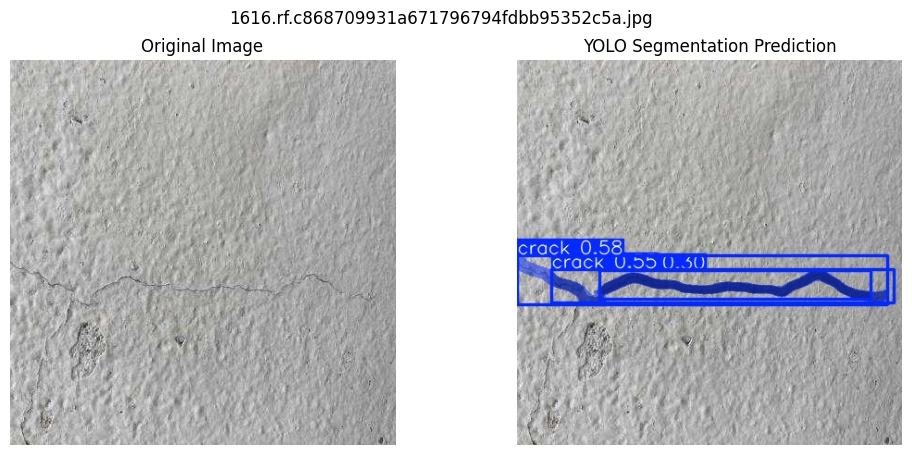

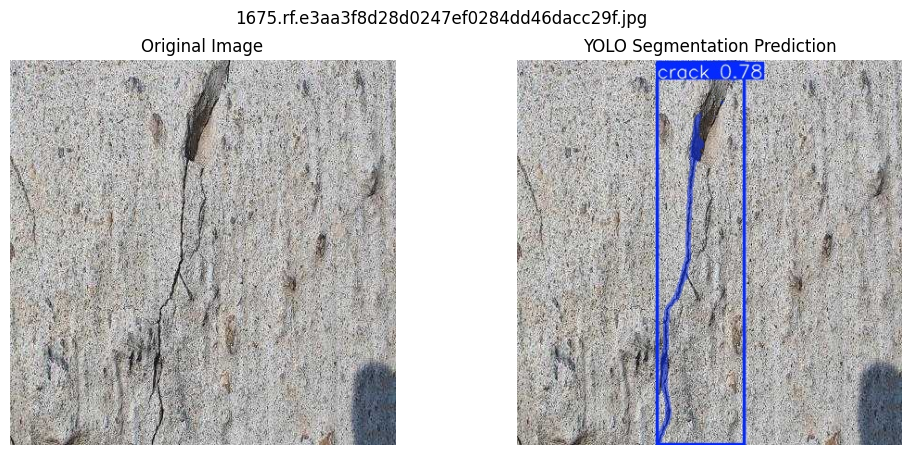

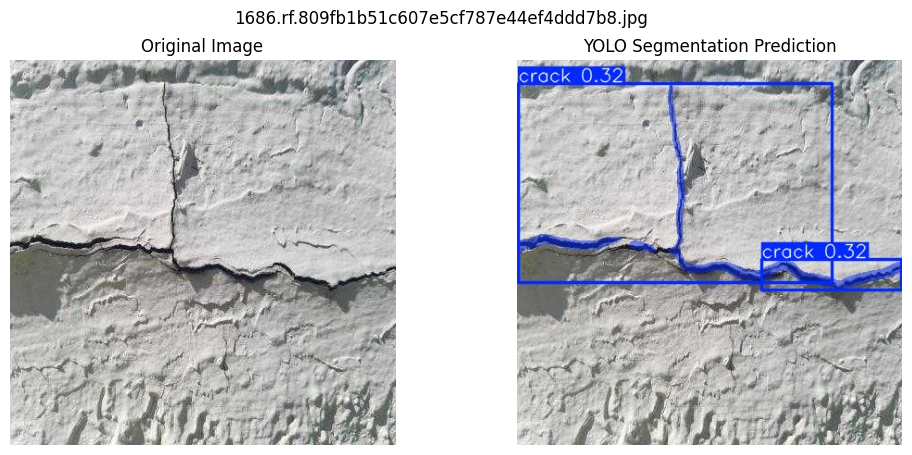

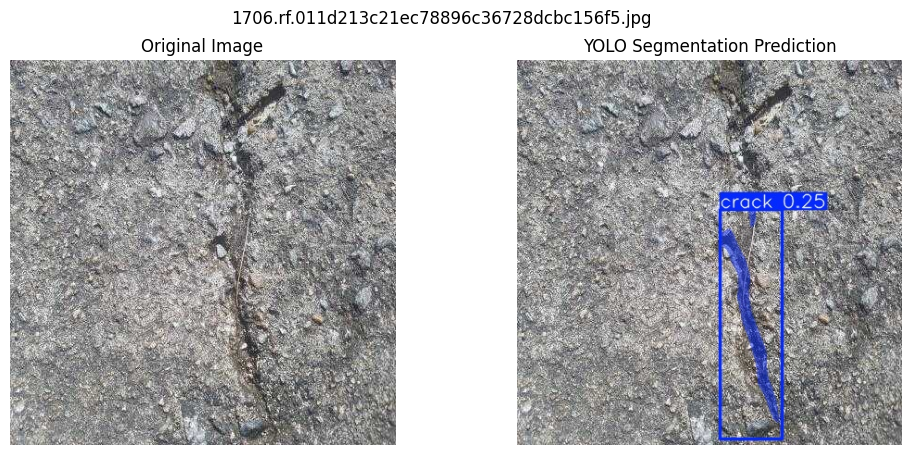

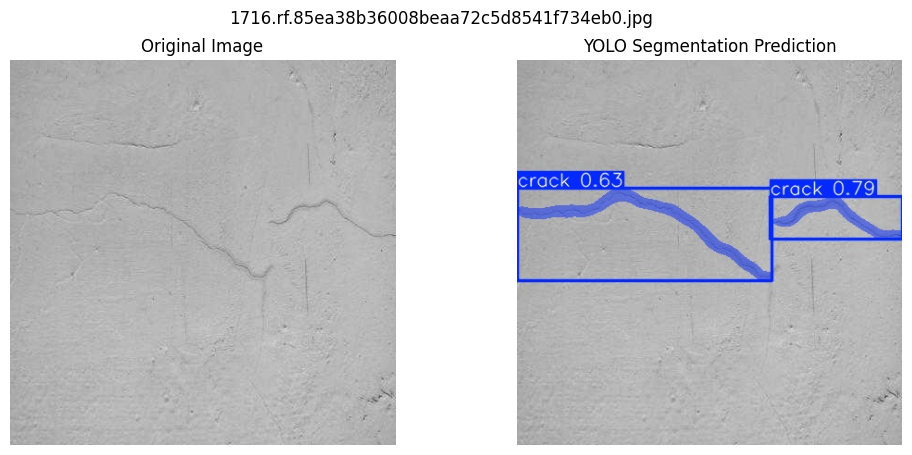

In [28]:
import os
import glob
import cv2
import matplotlib.pyplot as plt

test_dir = "/content/InfraScan_YOLO/images/test"

prediction_dir = (
    "/content/drive/MyDrive/InfraScan/"
    "segmentation/test_predictions"
)

originals = sorted(glob.glob(os.path.join(test_dir, "*.jpg")))
predicted = sorted(glob.glob(os.path.join(prediction_dir, "*.jpg")))

print("Original images:", len(originals))
print("Prediction images:", len(predicted))

for original_path in originals[:5]:

    filename = os.path.basename(original_path)
    predicted_path = os.path.join(prediction_dir, filename)

    if not os.path.exists(predicted_path):
        print("Prediction missing:", filename)
        continue

    original = cv2.cvtColor(
        cv2.imread(original_path), cv2.COLOR_BGR2RGB
    )

    prediction = cv2.cvtColor(
        cv2.imread(predicted_path), cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(prediction)
    plt.title("YOLO Segmentation Prediction")
    plt.axis("off")

    plt.suptitle(filename)
    plt.show()

**Interpretation.** In four of the five examples the predicted mask follows the main visible crack closely. Three weaknesses are also visible:

- A single long crack can be split into several overlapping detections (three in the first image, two in the third), so the number of detected instances can over-count the cracks.
- Fainter cracks are not always detected (for example the thin lines in the fifth image).
- In the fourth image (`1706.rf.011d...`) only the lower part of the visible crack is detected, with a confidence of 0.25, just above the threshold.

These examples agree with the moderate recall and mask scores reported in Section 15.1.

## 16. Results Summary and Saved Artifacts

This section checks that the files needed later exist, reads the saved metric files back from Google Drive and summarises the test results of both models.

### 16.1 Artifact audit

Checks that the checkpoints, the metric files and the prediction folder exist and prints the size of each file.

In [6]:
import os

paths = {
    "ResNet18 best checkpoint":
    "/content/drive/MyDrive/InfraScan/classification/checkpoints/resnet18_best.pth",

    "ResNet18 test metrics":
    "/content/drive/MyDrive/InfraScan/classification/outputs/resnet18_test_metrics.json",

    "YOLO best checkpoint":
    "/content/drive/MyDrive/InfraScan/segmentation/yolov8n_seg_run1/weights/best.pt",

    "YOLO last checkpoint":
    "/content/drive/MyDrive/InfraScan/segmentation/yolov8n_seg_run1/weights/last.pt",

    "YOLO training results":
    "/content/drive/MyDrive/InfraScan/segmentation/yolov8n_seg_run1/results.csv",

    "YOLO test metrics":
    "/content/drive/MyDrive/InfraScan/segmentation/test_evaluation/test_metrics.json",

    "YOLO prediction folder":
    "/content/drive/MyDrive/InfraScan/segmentation/test_predictions"
}

print("=" * 60)
print("INFRASCAN FINAL FILE AUDIT")
print("=" * 60)

for name, path in paths.items():
    exists = os.path.exists(path)
    print(f"{'FOUND' if exists else 'MISSING'} | {name}")

    if exists and os.path.isfile(path):
        print(f"  Size: {os.path.getsize(path) / (1024*1024):.2f} MB")

INFRASCAN FINAL FILE AUDIT
FOUND | ResNet18 best checkpoint
  Size: 128.04 MB
FOUND | ResNet18 test metrics
  Size: 0.00 MB
FOUND | YOLO best checkpoint
  Size: 6.68 MB
FOUND | YOLO last checkpoint
  Size: 6.68 MB
FOUND | YOLO training results
  Size: 0.01 MB
FOUND | YOLO test metrics
  Size: 0.00 MB
FOUND | YOLO prediction folder


All seven items are present. The ResNet18 checkpoint (128.04 MB) is much larger than the YOLO weights (6.68 MB) because it also stores the optimiser state and the training history (see Section 16.4).

### 16.2 Output folder structure

Lists the files saved under `InfraScan/` on Google Drive. The `combined_inference` folder is created later, in Section 18.2.

In [4]:
import os

root = "/content/drive/MyDrive/InfraScan"

for current, dirs, files in os.walk(root):
    level = current.replace(root, "").count(os.sep)

    if level <= 4:
        print("\n" + current)
        for file in files:
            print("  ", file)


/content/drive/MyDrive/InfraScan

/content/drive/MyDrive/InfraScan/classification

/content/drive/MyDrive/InfraScan/classification/outputs
   split_v1.csv
   resnet18_test_metrics.json

/content/drive/MyDrive/InfraScan/classification/checkpoints
   resnet18_best.pth

/content/drive/MyDrive/InfraScan/segmentation

/content/drive/MyDrive/InfraScan/segmentation/yolov8n_seg_run1
   args.yaml
   labels.jpg
   train_batch0.jpg
   train_batch1.jpg
   train_batch2.jpg
   train_batch18600.jpg
   train_batch18601.jpg
   train_batch18602.jpg
   val_batch0_labels.jpg
   val_batch0_pred.jpg
   val_batch1_labels.jpg
   val_batch1_pred.jpg
   val_batch2_labels.jpg
   val_batch2_pred.jpg
   BoxPR_curve.png
   BoxF1_curve.png
   results.csv
   BoxP_curve.png
   BoxR_curve.png
   MaskPR_curve.png
   MaskF1_curve.png
   MaskP_curve.png
   MaskR_curve.png
   confusion_matrix_normalized.png
   confusion_matrix.png
   results.png

/content/drive/MyDrive/InfraScan/segmentation/yolov8n_seg_run1/weights
   la

The segmentation run folder contains the training curves (`results.png`), confusion matrices, precision, recall and F1 curves, sample training and validation batches, `results.csv` and both weight files. The test evaluation folder contains the same kinds of plots for the test split together with `test_metrics.json`.

### 16.3 Saved metric files

Reads the saved classification and segmentation metric files and shows the last five rows of the YOLO training history (`results.csv`).

In [7]:
import json
import pandas as pd
import os

# 1. Classification test metrics
classification_path = (
    "/content/drive/MyDrive/InfraScan/classification/"
    "outputs/resnet18_test_metrics.json"
)

print("=" * 55)
print("RESNET18 TEST METRICS")
print("=" * 55)

with open(classification_path, "r") as f:
    classification_metrics = json.load(f)

print(json.dumps(classification_metrics, indent=4))


# 2. YOLO test metrics
yolo_path = (
    "/content/drive/MyDrive/InfraScan/segmentation/"
    "test_evaluation/test_metrics.json"
)

print("\n" + "=" * 55)
print("YOLO TEST METRICS")
print("=" * 55)

with open(yolo_path, "r") as f:
    yolo_metrics = json.load(f)

print(json.dumps(yolo_metrics, indent=4))


# 3. YOLO training history
csv_path = (
    "/content/drive/MyDrive/InfraScan/segmentation/"
    "yolov8n_seg_run1/results.csv"
)

history = pd.read_csv(csv_path)
history.columns = history.columns.str.strip()

print("\nTraining history shape:", history.shape)
print("\nLast 5 training epochs:")
display(history.tail())

RESNET18 TEST METRICS
{
    "model": "ResNet18",
    "best_epoch": 5,
    "validation_accuracy": 0.9337535374324673,
    "test_accuracy": 0.9367030965391621,
    "precision_cracked": 0.8813886210221794,
    "recall_cracked": 0.6785449146250928,
    "f1_cracked": 0.7667785234899329,
    "confusion_matrix": [
        [
            7314,
            123
        ],
        [
            433,
            914
        ]
    ]
}

YOLO TEST METRICS
{
    "metrics/precision(B)": 0.9196240689969134,
    "metrics/recall(B)": 0.6418918918918919,
    "metrics/mAP50(B)": 0.7540070778809158,
    "metrics/mAP50-95(B)": 0.5434020841717336,
    "metrics/precision(M)": 0.8277746896859767,
    "metrics/recall(M)": 0.581081081081081,
    "metrics/mAP50(M)": 0.6174300535932422,
    "metrics/mAP50-95(M)": 0.2243257672488294,
    "fitness": 0.767727851420563
}

Training history shape: (50, 23)

Last 5 training epochs:


,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/dfl_loss,train/sem_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),...,metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/dfl_loss,val/sem_loss,lr/pg0,lr/pg1,lr/pg2
45,46,3037.52,0.67147,1.04210,0.64799,1.01003,0,0.85410,0.75904,0.80493,...,0.70359,0.25203,0.86662,1.16154,0.82507,0.87154,0,0.000109,0.000109,0.000109
46,47,3097.27,0.66558,1.04377,0.63466,1.00971,0,0.83787,0.74715,0.80431,...,0.72723,0.25361,0.84731,1.17070,0.81776,0.85423,0,0.000089,0.000089,0.000089
47,48,3157.58,0.65278,1.02621,0.61611,0.99969,0,0.84696,0.74699,0.80363,...,0.70935,0.25516,0.86223,1.16735,0.82773,0.87015,0,0.000069,0.000069,0.000069
48,49,3218.01,0.64166,1.01649,0.61057,0.99661,0,0.86155,0.71888,0.80121,...,0.70609,0.25296,0.85625,1.16094,0.80505,0.86017,0,0.000050,0.000050,0.000050
49,50,3279.75,0.63471,1.02110,0.60647,0.99532,0,0.86513,0.72289,0.79368,...,0.69992,0.25012,0.85112,1.16052,0.81999,0.86687,0,0.000030,0.000030,0.000030


**Test results at a glance.** The two tables use different datasets and different metrics and must not be merged into a single score.

*Classification: ResNet18, SDNET2018 test split (8,784 images)*

| Accuracy | Precision (cracked) | Recall (cracked) | F1 (cracked) |
|---|---|---|---|
| 93.67% | 0.8814 | 0.6785 | 0.7668 |

*Segmentation: YOLOv8n-seg, Crack-Seg test split (112 images, 148 cracks)*

| | Precision | Recall | mAP50 | mAP50-95 |
|---|---|---|---|---|
| Box | 0.920 | 0.642 | 0.754 | 0.543 |
| Mask | 0.828 | 0.581 | 0.617 | 0.224 |

### 16.4 Checkpoint and training-history inspection

Confirms what the ResNet18 checkpoint contains and finds the epoch with the highest validation mask mAP50-95 in the YOLO training history.

In [8]:
import torch
import pandas as pd

# ResNet checkpoint inspection
resnet_path = (
    "/content/drive/MyDrive/InfraScan/"
    "classification/checkpoints/resnet18_best.pth"
)

checkpoint = torch.load(
    resnet_path,
    map_location="cpu",
    weights_only=True
)

print("RESNET CHECKPOINT TYPE:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys())[:20])

# YOLO best epoch analysis
csv_path = (
    "/content/drive/MyDrive/InfraScan/"
    "segmentation/yolov8n_seg_run1/results.csv"
)

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

metric = "metrics/mAP50-95(M)"

best_row = df.loc[df[metric].idxmax()]

print("\nYOLO BEST VALIDATION EPOCH")
print("Epoch:", int(best_row["epoch"]) + 1)
print("Mask mAP50-95:", best_row[metric])
print("Mask mAP50:", best_row["metrics/mAP50(M)"])

RESNET CHECKPOINT TYPE: <class 'dict'>
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_acc', 'history']

YOLO BEST VALIDATION EPOCH
Epoch: 44
Mask mAP50-95: 0.26015
Mask mAP50: 0.72316


The ResNet18 checkpoint holds the epoch, the model weights, the optimiser state, the best validation accuracy and the history. In the YOLO training history the highest validation mask mAP50-95 is 0.260 (mask mAP50 0.723).

**Note on the epoch number.** The cell prints this as epoch 44. The `epoch` column of `results.csv` already starts at 1 (the last five rows in Section 16.3 are numbered 46 to 50), and the cell adds 1 to it, so the printed number is one too high. These scores belong to epoch 43. The metric values themselves are not affected. This analysis is descriptive only: Ultralytics selects `best.pt` with its own combined fitness score, which does not have to coincide with the epoch that has the highest mask mAP50-95.

## 17. Integrated Inference Pipeline

The pipeline applies both trained models to one input image and returns their results together.

1. **ResNet18 (classification).** The image is resized to 224 x 224 px and normalised. The model output is converted to probabilities, and the more probable class (Cracked or Uncracked) is reported with its probability as the confidence.
2. **YOLOv8n-seg (segmentation).** The image is processed at 416 px with a confidence threshold of 0.25. The pipeline reports the number of detected crack instances, whether masks are available, and an annotated image with the predicted masks and boxes.

The two models run independently on the same image. No rule links them (for example, segmentation is not skipped when the classifier answers Uncracked), and the pipeline as a whole has not been evaluated against ground truth. The accuracy of each model is as reported in Sections 11 and 15. Inference is run on the CPU.

ResNet18 was trained on SDNET2018 (256 x 256 px close-up patches of concrete surfaces), whereas the demonstration images in Section 18 come from Crack-Seg. The classifier output on those images has therefore not been validated.

### 17.1 Load both models

Loads the best ResNet18 checkpoint and the best YOLOv8n-seg weights from Google Drive for CPU inference, and defines the classification preprocessing (the same as the evaluation transformation in Section 9.2).

In [14]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from ultralytics import YOLO
import os

# -----------------------------
# PATHS
# -----------------------------

resnet_path = (
    "/content/drive/MyDrive/InfraScan/"
    "classification/checkpoints/resnet18_best.pth"
)

yolo_path = (
    "/content/drive/MyDrive/InfraScan/"
    "segmentation/yolov8n_seg_run1/weights/best.pt"
)

# -----------------------------
# LOAD RESNET18
# -----------------------------

device = torch.device("cpu")

checkpoint = torch.load(
    resnet_path,
    map_location=device,
    weights_only=True
)

resnet = models.resnet18(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, 2)

resnet.load_state_dict(checkpoint["model_state_dict"])
resnet.to(device)
resnet.eval()

print("ResNet18 loaded successfully")

# -----------------------------
# LOAD YOLO
# -----------------------------

seg_model = YOLO(yolo_path)

print("YOLOv8n-seg loaded successfully")

# -----------------------------
# CLASSIFICATION TRANSFORM
# -----------------------------

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("\nBoth models are ready for CPU inference.")

ResNet18 loaded successfully
YOLOv8n-seg loaded successfully

Both models are ready for CPU inference.


### 17.2 Pipeline function

Defines `infrascan_predict(image_path)`, which runs classification and segmentation on one image, prints the result and returns the annotated image and the YOLO result object.

In [16]:
def infrascan_predict(image_path):

    if not os.path.exists(image_path):
        raise FileNotFoundError(image_path)

    image = Image.open(image_path).convert("RGB")

    # Classification
    input_tensor = transform(image).unsqueeze(0)

    with torch.no_grad():
        logits = resnet(input_tensor)
        probabilities = torch.softmax(logits, dim=1)

    predicted_class = probabilities.argmax(dim=1).item()

    class_names = {
        0: "Uncracked",
        1: "Cracked"
    }

    classification_result = class_names[predicted_class]
    confidence = probabilities[0][predicted_class].item()

    # Segmentation
    yolo_results = seg_model.predict(
        source=image_path,
        imgsz=416,
        conf=0.25,
        device="cpu",
        verbose=False
    )

    result = yolo_results[0]

    number_of_cracks = (
        len(result.boxes) if result.boxes is not None else 0
    )

    annotated_image = result.plot()

    print("========== INFRASCAN RESULT ==========")
    print("Classification:", classification_result)
    print("Classification confidence:", round(confidence * 100, 2), "%")
    print("Detected crack instances:", number_of_cracks)
    print("Segmentation masks available:", result.masks is not None)

    return annotated_image, result

### 17.3 Select test images

Collects the 112 Crack-Seg test images used to demonstrate the pipeline.

In [19]:
import glob
import os

test_dir = "/content/InfraScan_YOLO/images/test"

test_images = []

for ext in ["*.jpg", "*.jpeg", "*.png"]:
    test_images.extend(
        glob.glob(os.path.join(test_dir, ext))
    )

test_images = sorted(test_images)

print("Available test images:", len(test_images))
print("Sample paths:", test_images[:5])

Available test images: 112
Sample paths: ['/content/InfraScan_YOLO/images/test/1616.rf.c868709931a671796794fdbb95352c5a.jpg', '/content/InfraScan_YOLO/images/test/1675.rf.e3aa3f8d28d0247ef0284dd46dacc29f.jpg', '/content/InfraScan_YOLO/images/test/1686.rf.809fb1b51c607e5cf787e44ef4ddd7b8.jpg', '/content/InfraScan_YOLO/images/test/1706.rf.011d213c21ec78896c36728dcbc156f5.jpg', '/content/InfraScan_YOLO/images/test/1716.rf.85ea38b36008beaa72c5d8541f734eb0.jpg']


## 18. Sample Predictions and Output Analysis

### 18.1 Single image

Runs the pipeline on the first test image and displays the annotated result.

Testing: /content/InfraScan_YOLO/images/test/1616.rf.c868709931a671796794fdbb95352c5a.jpg
========== INFRASCAN RESULT ==========
Classification: Cracked
Classification confidence: 99.99 %
Detected crack instances: 3
Segmentation masks available: True


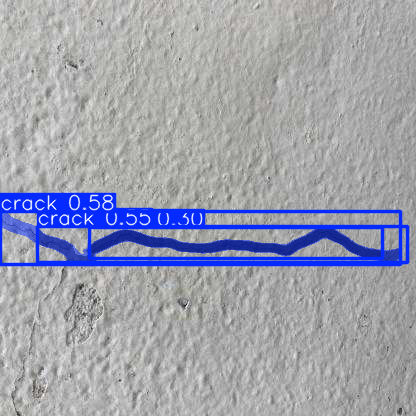

In [20]:
from IPython.display import display

sample_image = test_images[0]

print("Testing:", sample_image)

annotated_image, result = infrascan_predict(sample_image)

display(Image.fromarray(annotated_image[:, :, ::-1]))

The classifier predicts Cracked with 99.99% confidence, and the segmentation model detects three crack instances. This is the first image of Section 15.3, where three overlapping detections cover one long crack.

### 18.2 Ten test images

Runs both models on the first ten test images, collects the results in a table and saves it as `combined_results.csv` together with the annotated images in the `combined_inference` folder.

In [21]:
import pandas as pd
import os
from PIL import Image as PILImage

output_dir = (
    "/content/drive/MyDrive/InfraScan/"
    "combined_inference"
)

os.makedirs(output_dir, exist_ok=True)

records = []

for i, image_path in enumerate(test_images[:10]):

    image = PILImage.open(image_path).convert("RGB")
    input_tensor = transform(image).unsqueeze(0)

    # ResNet18 classification
    with torch.no_grad():
        logits = resnet(input_tensor)
        probs = torch.softmax(logits, dim=1)

    pred_class = probs.argmax(1).item()

    # YOLO segmentation
    yolo_result = seg_model.predict(
        source=image_path,
        imgsz=416,
        conf=0.25,
        device="cpu",
        verbose=False
    )[0]

    crack_count = (
        len(yolo_result.boxes)
        if yolo_result.boxes is not None else 0
    )

    # Save annotated prediction
    annotated = yolo_result.plot()
    output_path = os.path.join(
        output_dir, f"prediction_{i+1}.jpg"
    )

    PILImage.fromarray(
        annotated[:, :, ::-1]
    ).save(output_path)

    records.append({
        "image": os.path.basename(image_path),
        "classification": (
            "Cracked" if pred_class == 1 else "Uncracked"
        ),
        "classification_confidence": round(
            probs[0][pred_class].item(), 4
        ),
        "yolo_detected_instances": crack_count,
        "segmentation_mask_available": (
            yolo_result.masks is not None
        ),
        "annotated_image": output_path
    })

    print(f"Processed {i+1}/10")

df = pd.DataFrame(records)

csv_path = os.path.join(output_dir, "combined_results.csv")
df.to_csv(csv_path, index=False)

display(df)

print("\nResults saved:", csv_path)

Processed 1/10
Processed 2/10
Processed 3/10
Processed 4/10
Processed 5/10
Processed 6/10
Processed 7/10
Processed 8/10
Processed 9/10
Processed 10/10


,image,classification,classification_confidence,yolo_detected_instances,segmentation_mask_available,annotated_image
0,1616.rf.c868709931a671796794fdbb95352c5a.jpg,Cracked,0.9999,3,True,/content/drive/MyDrive/InfraScan/combined_infe...
1,1675.rf.e3aa3f8d28d0247ef0284dd46dacc29f.jpg,Cracked,0.9436,1,True,/content/drive/MyDrive/InfraScan/combined_infe...
2,1686.rf.809fb1b51c607e5cf787e44ef4ddd7b8.jpg,Cracked,0.9822,2,True,/content/drive/MyDrive/InfraScan/combined_infe...
3,1706.rf.011d213c21ec78896c36728dcbc156f5.jpg,Uncracked,0.8141,1,True,/content/drive/MyDrive/InfraScan/combined_infe...
4,1716.rf.85ea38b36008beaa72c5d8541f734eb0.jpg,Cracked,0.9977,2,True,/content/drive/MyDrive/InfraScan/combined_infe...
5,1722.rf.38b38f2e833309a4f35bfbf0432dffff.jpg,Cracked,0.9998,1,True,/content/drive/MyDrive/InfraScan/combined_infe...
6,1794.rf.7a03ca09d05e9e2941f768bc8570cb54.jpg,Cracked,0.8821,1,True,/content/drive/MyDrive/InfraScan/combined_infe...
7,1804.rf.7e39a73f7b0d1c4bdf8094006e0cf495.jpg,Cracked,0.9999,2,True,/content/drive/MyDrive/InfraScan/combined_infe...
8,1806.rf.8c87862452f4ce0232a666c180ec9942.jpg,Cracked,1.0000,1,True,/content/drive/MyDrive/InfraScan/combined_infe...
9,1813.rf.79f1af872f76dd8b46df4a83ed5f54c6.jpg,Cracked,0.9996,3,True,/content/drive/MyDrive/InfraScan/combined_infe...



Results saved: /content/drive/MyDrive/InfraScan/combined_inference/combined_results.csv


**Interpretation**

- **Classification.** Nine of the ten images are classified as Cracked (confidence 0.88 to 1.00). One image (`1706.rf.011d...`) is classified as Uncracked with a confidence of 0.81.
- **Segmentation.** The segmentation model detects between one and three crack instances in every image.
- **Disagreement.** The evaluation log in Section 15.1 reports no background images in the test split, so all ten images contain annotated cracks. The Uncracked prediction for image `1706.rf.011d...` is therefore most likely a classifier miss. The overlay in Section 15.3 shows a visible crack in that image, which the segmentation model detects only in part.
- **Scope.** This is a demonstration of the pipeline on ten images from a dataset different from the one the classifier was trained on. It is not an evaluation, and the agreement between the two models should not be read as accuracy.

## 19. Standalone Inference Script

The same pipeline is saved as a command-line script, `inference.py`, in the `combined_inference` folder on Google Drive so that it can be run outside the notebook:

```
python inference.py --image <path to image> --output <output folder>
```

The script loads both models on the CPU, writes an annotated image (`annotated_prediction.jpg`) and a JSON report (`prediction.json`) to the output folder, and prints the report. The default output folder is `/content/InfraScan_Output`. The model paths in the script are absolute Google Drive paths, so Drive must be mounted when it runs.

### 19.1 Write the script

The `%%writefile` command saves the cell content as `inference.py`. The target folder was created in Section 18.2.

In [22]:
%%writefile /content/drive/MyDrive/InfraScan/combined_inference/inference.py

import os
import json
import argparse
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from ultralytics import YOLO

RESNET_PATH = (
    "/content/drive/MyDrive/InfraScan/"
    "classification/checkpoints/resnet18_best.pth"
)

YOLO_PATH = (
    "/content/drive/MyDrive/InfraScan/"
    "segmentation/yolov8n_seg_run1/weights/best.pt"
)

DEVICE = "cpu"

# Load classification model
checkpoint = torch.load(
    RESNET_PATH,
    map_location=DEVICE,
    weights_only=True
)

resnet = models.resnet18(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, 2)
resnet.load_state_dict(checkpoint["model_state_dict"])
resnet.eval()

# Load segmentation model
seg_model = YOLO(YOLO_PATH)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


def predict_image(image_path, output_dir):

    os.makedirs(output_dir, exist_ok=True)

    image = Image.open(image_path).convert("RGB")

    # Classification
    tensor = transform(image).unsqueeze(0)

    with torch.no_grad():
        probabilities = torch.softmax(resnet(tensor), dim=1)

    predicted_class = probabilities.argmax(1).item()

    class_name = (
        "Cracked" if predicted_class == 1 else "Uncracked"
    )

    confidence = probabilities[0][predicted_class].item()

    # Segmentation
    result = seg_model.predict(
        source=image_path,
        imgsz=416,
        conf=0.25,
        device=DEVICE,
        verbose=False
    )[0]

    crack_count = len(result.boxes) if result.boxes is not None else 0

    annotated = result.plot()

    output_image = os.path.join(
        output_dir, "annotated_prediction.jpg"
    )

    import cv2
    cv2.imwrite(output_image, annotated)

    report = {
        "image": os.path.basename(image_path),
        "classification": class_name,
        "classification_confidence": round(confidence, 4),
        "detected_instances": crack_count,
        "segmentation_mask_available": result.masks is not None,
        "annotated_image": output_image
    }

    report_path = os.path.join(output_dir, "prediction.json")

    with open(report_path, "w") as f:
        json.dump(report, f, indent=4)

    print(json.dumps(report, indent=4))

    return report


if __name__ == "__main__":

    parser = argparse.ArgumentParser()
    parser.add_argument("--image", required=True)
    parser.add_argument(
        "--output",
        default="/content/InfraScan_Output"
    )

    args = parser.parse_args()

    predict_image(args.image, args.output)

Writing /content/drive/MyDrive/InfraScan/combined_inference/inference.py


### 19.2 Check the saved file

Confirms that the script exists.

In [23]:
import os

script_path = (
    "/content/drive/MyDrive/InfraScan/"
    "combined_inference/inference.py"
)

print("Inference script exists:", os.path.exists(script_path))

if os.path.exists(script_path):
    print("File size:", os.path.getsize(script_path), "bytes")
    print("Script saved successfully.")

Inference script exists: True
File size: 2641 bytes
Script saved successfully.


### 19.3 Test run

Runs the script as a separate process on the first test image.

In [24]:
import subprocess

script_path = (
    "/content/drive/MyDrive/InfraScan/"
    "combined_inference/inference.py"
)

test_image = (
    "/content/InfraScan_YOLO/images/test/"
    "1616.rf.c868709931a671796794fdbb95352c5a.jpg"
)

output_dir = (
    "/content/drive/MyDrive/InfraScan/"
    "combined_inference/script_test"
)

command = [
    "python",
    script_path,
    "--image", test_image,
    "--output", output_dir
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nSTDOUT:")
print(result.stdout)

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr)

Return code: 0

STDOUT:
{
    "image": "1616.rf.c868709931a671796794fdbb95352c5a.jpg",
    "classification": "Cracked",
    "classification_confidence": 0.9999,
    "detected_instances": 3,
    "segmentation_mask_available": true,
    "annotated_image": "/content/drive/MyDrive/InfraScan/combined_inference/script_test/annotated_prediction.jpg"
}



The script finishes with return code 0 and reports the same result as the in-notebook pipeline: Cracked with a confidence of 0.9999, three detected instances and masks available.

### 19.4 Output files

Lists the files written by the test run, then shows the annotated image and the JSON report.

In [25]:
import os

output_dir = (
    "/content/drive/MyDrive/InfraScan/"
    "combined_inference/script_test"
)

for file in os.listdir(output_dir):
    path = os.path.join(output_dir, file)
    print(file, round(os.path.getsize(path) / 1024, 2), "KB")

annotated_prediction.jpg 67.71 KB
prediction.json 0.31 KB


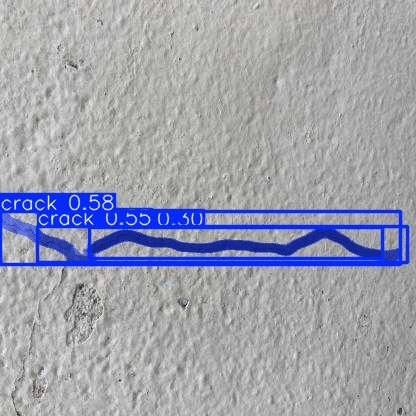

Prediction Report:
{
    "image": "1616.rf.c868709931a671796794fdbb95352c5a.jpg",
    "classification": "Cracked",
    "classification_confidence": 0.9999,
    "detected_instances": 3,
    "segmentation_mask_available": true,
    "annotated_image": "/content/drive/MyDrive/InfraScan/combined_inference/script_test/annotated_prediction.jpg"
}


In [26]:
from PIL import Image
from IPython.display import display
import os
import json

output_dir = "/content/drive/MyDrive/InfraScan/combined_inference/script_test"

# Display annotated prediction
image_path = os.path.join(output_dir, "annotated_prediction.jpg")
display(Image.open(image_path))

# Read prediction report
json_path = os.path.join(output_dir, "prediction.json")

with open(json_path, "r") as f:
    report = json.load(f)

print("Prediction Report:")
print(json.dumps(report, indent=4))

## 20. Limitations

1. **Separate evaluation.** Classification and segmentation are evaluated separately on different datasets. The integrated pipeline has no ground-truth evaluation, so no combined accuracy exists.
2. **Domain mismatch in the pipeline.** ResNet18 was trained on 256 x 256 px close-up patches from one university campus (SDNET2018), while the pipeline demonstration uses Crack-Seg images, on which the classifier has not been validated. The Uncracked prediction for image `1706.rf.011d...` in Section 18.2 shows that the two models can disagree.
3. **Classifier recall.** Recall for cracked images is 0.68, with 433 of 1,347 cracked test images missed. The checkpoint was selected by validation accuracy, and training used neither class weights nor threshold tuning although only about 15% of the images are cracked.
4. **Limited data and single runs.** SDNET2018 is derived from 230 photographs, and the validation and test sets contain 32 and 36 photographs, so the estimates are uncertain. Only one split and one training run per model were made, and the ResNet18 run is not seeded.
5. **Segmentation quality.** Mask mAP50-95 on the test split is 0.224 and mask recall is 0.58. The test split has only 112 images (148 cracks). Training used images resized to 416 px, which may hide fine cracks. A long crack is sometimes split into several detections, so the number of detected instances is not a reliable crack count.
6. **Crack-Seg not audited.** Crack-Seg was used with its supplied splits. Unlike SDNET2018, it was not checked for duplicate or near-duplicate images across splits.
7. **Scope of the assessment.** The notebook detects and localises cracks. It does not measure crack width, length or severity, and it does not distinguish crack types or other kinds of damage.

## 21. Future Improvements

- **Raise classifier recall.** Use a class-weighted loss or a lower decision threshold chosen on the validation set, and select checkpoints by F1 or recall of the cracked class instead of accuracy.
- **Make the evaluation more reliable.** Repeat training with several seeds or use block-wise cross-validation, report confidence intervals, and test on images from other structures and cameras.
- **Evaluate the pipeline as a whole.** Collect a shared test set with both image-level labels and crack masks, so that the integrated pipeline can be evaluated end to end.
- **Improve segmentation.** Try a higher input resolution or image tiling for thin cracks, larger YOLOv8 variants and tuned training, and merge overlapping detections of the same crack before counting.
- **Extend the assessment.** Derive crack length and width from the masks using a known image scale, and add severity levels.
- **Audit Crack-Seg.** Check for duplicate images across its splits.

## 22. Conclusion

This notebook implements the InfraScan workflow from data preparation to inference. The SDNET2018 data were audited, 15 duplicate or conflicting files were removed, and a leakage-safe 70/15/15 split of 56,077 images was built by grouping neighbouring photographs into blocks. A fine-tuned ResNet18 classifies images as cracked or uncracked with a test accuracy of 93.67%, a precision of 0.881, a recall of 0.679 and an F1 score of 0.767 for the cracked class. A fine-tuned YOLOv8n-seg localises cracks on Crack-Seg with a test box mAP50 of 0.754 and a mask mAP50 of 0.617 (mask mAP50-95 of 0.224). Both models are combined in an inference pipeline, which is also saved as a command-line script and was demonstrated on ten test images.

The classification and segmentation results come from different datasets and are not combined into a single score, and the integrated pipeline itself has not been evaluated against ground truth. The main weaknesses are the classifier's recall for cracked images, the moderate mask quality at strict overlap thresholds, and the small, single-site data. The current system is a working prototype for detecting and localising cracks. Measuring crack size and severity and evaluating the pipeline as a whole remain for future work.